# FairPrice Auto

What we do in this notebook:
1. Load the CSV and check the columns
2. Rows by country and currency (how many are Italian?)
3. Missing values, duplicates, data types
4. Distributions of price, mileage, registration date, power
5. Choice of the training set (Italy only or all countries)
6. Exclusion of columns with personal or identifying data
7. Summary table of quality issues

> Note: in this notebook we **do not modify** the data, we observe and measure it.

In [1]:
import os
import ast
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import json
import joblib
import shap
import lightgbm as lgb
from sklearn.metrics import r2_score, roc_auc_score, average_precision_score, recall_score, confusion_matrix
from sklearn.model_selection import train_test_split, KFold, cross_val_predict
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import IsolationForest

# Settings to see more complete tables
pd.set_option("display.max_colwidth", None)
pd.set_option("display.max_columns", 100)
pd.set_option("display.max_rows", 100)
pd.set_option("display.precision", 2)

# Paths (relative to the notebook folder).
CSV_PATH = "dataset/autoscout24_dataset_20251108.csv"     
DATA_FOLDER = "data"
AUDIT_FOLDER = "data/audit"
FIGURES_FOLDER = "figures"
MODEL_DIR = DATA_FOLDER + "/models"
DATASET_FILE = DATA_FOLDER + "/model_dataset.csv"
KEYS_FILE = DATA_FOLDER + "/ad_keys.csv"

SEED = 1234
TEST_SHARE = 0.20

# We create the output folders if they do not exist
for folder in [DATA_FOLDER, AUDIT_FOLDER, FIGURES_FOLDER, MODEL_DIR]:
    os.makedirs(folder, exist_ok=True)

## 1. Dataset Exploration
**Goal:** Preliminary exploration of dataset features and values.

### 1.1. Dataset loading

In [2]:
df = pd.read_csv(CSV_PATH, low_memory=False)

total_rows = len(df)
print("Number of rows:", df.shape[0])
print("Number of columns:", df.shape[1])

Number of rows: 118382
Number of columns: 75


In [3]:
# List of all columns with their order number
number = 1
for name in df.columns:
    print(number, name)
    number = number + 1

1 id
2 description
3 ratings_average
4 ratings_count
5 ratings_recommend_percentage
6 price_currency
7 price
8 price_tax_deductible
9 price_negotiable
10 price_net
11 price_vat_rate
12 vin
13 make
14 model
15 model_version
16 german_hsn_tsn
17 mileage_km_raw
18 mileage_km
19 registration_date
20 production_year
21 vehicle_type
22 body_type
23 nr_seats
24 nr_doors
25 body_color
26 paint_type
27 body_color_original
28 upholstery
29 upholstery_color
30 power_kw
31 power_hp
32 transmission
33 gears
34 drive_train
35 cylinders
36 cylinders_volume_cc
37 weight_kg
38 has_particle_filter
39 fuel_category
40 primary_fuel
41 electric_range_km
42 electric_range_city_km
43 fuel_cons_comb_l100_km
44 fuel_cons_city_l100_km
45 fuel_cons_highway_l100_km
46 co2_emission_grper_km
47 fuel_cons_comb_l100_wltp_km
48 fuel_cons_electric_comb_l100_wltp_km
49 co2_emission_grper_wltp_km
50 equipment_comfort
51 equipment_entertainment
52 equipment_extra
53 equipment_safety
54 is_used
55 is_new
56 is_preregistere

In [4]:
expected_columns = ["id", "vin", "country_code", "price_currency", "price",
                  "mileage_km", "registration_date", "power_kw", "power_hp",
                  "make", "model", "street", "zip", "seller_company_name",
                  "description"]

for name in expected_columns:
    if name in df.columns:
        print("OK        ", name)
    else:
        print("MISSING  ", name)

# Let's also count the optional equipment columns (equipment_...)
n_equipment = 0
for name in df.columns:
    if name.startswith("equipment_"):
        n_equipment = n_equipment + 1
print()
print("equipment_* columns:", n_equipment)

OK         id
OK         vin
OK         country_code
OK         price_currency
OK         price
OK         mileage_km
OK         registration_date
OK         power_kw
OK         power_hp
OK         make
OK         model
OK         street
OK         zip
OK         seller_company_name
OK         description

equipment_* columns: 4


In [5]:
issues = []

def percentage(part, total):
    return round(part / total * 100, 2)

def log_issue(category, description, quantity):
    row = {
        "category": category,
        "description": description,
        "involved_rows": int(quantity),
        "percentage_of_total": percentage(quantity, total_rows),
    }
    issues.append(row)

### 1.2. Rows by country and currency

Key question: **how many rows are Italian?**

In [6]:
rows_per_country = df["country_code"].value_counts(dropna=False)
countries_percentage = df["country_code"].value_counts(normalize=True, dropna=False) * 100

countries_table = pd.DataFrame({
    "rows": rows_per_country,
    "percentage": countries_percentage,
})
countries_table

,rows,percentage
country_code,,
DE,45611,38.53
IT,23957,20.24
NL,17059,14.41
BE,9582,8.09
ES,8015,6.77
AT,7213,6.09
FR,6141,5.19
LU,789,0.67
NaN,15,0.01


In [7]:
# Italian rows
italian_rows = df[df["country_code"] == "IT"]
n_italy = len(italian_rows)

print("Italian rows:", n_italy)
print("Percentage of total:", percentage(n_italy, total_rows), "%")

Italian rows: 23957
Percentage of total: 20.24 %


In [8]:
# Rows by currency
print(df["price_currency"].value_counts(dropna=False))
print()

pd.crosstab(df["country_code"], df["price_currency"])

price_currency
EUR    118382
Name: count, dtype: int64



price_currency,EUR
country_code,
AT,7213
BE,9582
DE,45611
ES,8015
FR,6141
IT,23957
LU,789
NL,17059


In [9]:
# Prices in a currency other than EUR (missing ones are counted in here)
n_non_euro = (df["price_currency"] != "EUR").sum()
print("Rows with currency other than EUR (or missing):", n_non_euro)

log_issue("currency", "price not in EUR (or currency missing)", n_non_euro)

Rows with currency other than EUR (or missing): 0


### 1.3. Missing values per column

In [10]:
# How many missing values does each column have?
missing = df.isna().sum()
missing_percentage = missing / total_rows * 100

missing_table = pd.DataFrame({
    "missing": missing,
    "percentage": missing_percentage,
})
missing_table = missing_table.sort_values("percentage", ascending=False)

missing_table.to_csv(AUDIT_FOLDER + "/missing_values.csv")

missing_table

,missing,percentage
fuel_cons_highway_l100_km,118382,100.00
has_warranty,118382,100.00
warranty,118382,100.00
fuel_cons_city_l100_km,118382,100.00
electric_range_city_km,117743,99.46
fuel_cons_electric_comb_l100_wltp_km,113456,95.84
electric_range_km,105637,89.23
production_year,96110,81.19
co2_emission_grper_km,93571,79.04
fuel_cons_comb_l100_wltp_km,88112,74.43


In [11]:
MISSING_THRESHOLD = 20   # percentage

for column_name in missing_table.index:
    perc = missing_table.loc[column_name, "percentage"]
    if perc >= MISSING_THRESHOLD:   # type: ignore
        description = "column " + column_name + " with at least " + str(MISSING_THRESHOLD) + "% missing"
        log_issue("missing values", description, missing_table.loc[column_name, "missing"])

### 1.4. Duplicates

We check three things: completely identical rows, repeated `id`s, repeated `vin`s.
Missing VINs are excluded from the count, otherwise they would be counted as "equal to each other".

In [12]:
# Completely identical rows
n_identical_rows = df.duplicated().sum()

# Repeated ids
valid_ids = df["id"].dropna()
n_repeated_ids = valid_ids.duplicated().sum()

# Missing and repeated vins
n_missing_vins = df["vin"].isna().sum()
valid_vins = df["vin"].dropna()
n_repeated_vins = valid_vins.duplicated().sum()

print("Completely identical rows:", n_identical_rows)
print("Repeated ids:             ", n_repeated_ids)
print("Missing vins:             ", n_missing_vins)
print("Repeated vins (excluding missing):", n_repeated_vins)

log_issue("duplicates", "completely identical rows", n_identical_rows)
log_issue("duplicates", "repeated id", n_repeated_ids)
log_issue("duplicates", "repeated vin (excluding missing)", n_repeated_vins)

Completely identical rows: 0
Repeated ids:              0
Missing vins:              78160
Repeated vins (excluding missing): 2644


In [13]:
repeated_vins_filter = df["vin"].duplicated(keep=False) & df["vin"].notna()
repeated_vins_rows = df[repeated_vins_filter]
repeated_vins_rows = repeated_vins_rows.sort_values("vin")

print("Rows involved in repeated VINs:", len(repeated_vins_rows))
print("Distinct repeated VINs:", repeated_vins_rows["vin"].nunique())

columns_to_view = ["vin", "country_code", "price", "mileage_km_raw",
                     "registration_date", "seller_type"]
repeated_vins_rows[columns_to_view].head(20)

Rows involved in repeated VINs: 4489
Distinct repeated VINs: 1845


,vin,country_code,price,mileage_km_raw,registration_date,seller_type
118310,00000000000000000,IT,38900.0,65000.0,2020-03-01,Dealer
70002,00000000000000000,IT,30490.0,55700.0,2021-01-01,Dealer
67965,00000000000000000,IT,11500.0,134000.0,2015-02-01,Dealer
101020,00000000000000000,IT,61500.0,2000.0,2025-05-01,Dealer
44973,00000000000000000,IT,230000.0,15000.0,2023-01-01,Dealer
33856,00000000000000000,IT,28500.0,93400.0,2020-06-01,Dealer
51318,00000000000000000,IT,80900.0,23700.0,2023-09-01,Dealer
24977,00000000000000000,IT,65700.0,24900.0,2025-03-01,Dealer
101769,00000000000000000,IT,5699.0,149000.0,2011-06-01,Dealer
85790,00000000000000000,IT,9999.0,124000.0,2015-05-01,Dealer


### 1.5. Data types

We are mainly interested in checking that the numerical columns (price, km, power) are really numerical
and not text, and in understanding how the date is read.

In [14]:
types = pd.DataFrame({
    "type": df.dtypes,
    "distinct_values": df.nunique(),
})
types

,type,distinct_values
id,object,118382
description,object,107516
ratings_average,object,42
ratings_count,float64,737
ratings_recommend_percentage,float64,63
price_currency,object,1
price,float64,16476
price_tax_deductible,bool,2
price_negotiable,bool,2
price_net,float64,14414


In [15]:
# Columns that contain numbers but are read as text
print(df[["mileage_km", "mileage_km_raw"]].head())
print()
print(df[["weight_kg"]].head())
print()
print(df[["ratings_average"]].dropna().head())

n_km_text = df["mileage_km"].notna().sum()
n_weight_text = df["weight_kg"].notna().sum()
n_ratings_text = df["ratings_average"].notna().sum()

log_issue("data type", "mileage_km is text (numerical mileage_km_raw exists)", n_km_text)
log_issue("data type", "weight_kg is text (e.g. 1,945 kg)", n_weight_text)
log_issue("data type", "ratings_average is text with decimal comma", n_ratings_text)

  mileage_km  mileage_km_raw
0  10,500 km         10500.0
1  55,609 km         55609.0
2  18,200 km         18200.0
3      10 km            10.0
4  74,602 km         74602.0

  weight_kg
0    894 kg
1  1,945 kg
2  1,760 kg
3  2,075 kg
4  2,165 kg

  ratings_average
2             4,8
3             4,2
7             4,3
8             5,0
9             4,7


### 1.6. Distributions of main variables

For each variable we look at: minimum, maximum, median and some percentiles.
The high percentiles (95%, 99%) show us how "long" the tails are.

In [16]:
numerical_columns = ["price", "mileage_km_raw", "power_kw", "power_hp"]

for name in numerical_columns:
    print("=== " + name + " ===")
    print(df[name].describe())
    print()
    print("Percentiles 1%, 5%, 50%, 95%, 99%:")
    print(df[name].quantile([0.01, 0.05, 0.5, 0.95, 0.99]))
    print()

=== price ===
count    1.18e+05
mean     5.75e+04
std      1.10e+05
min      1.00e+00
25%      2.40e+04
50%      4.00e+04
75%      7.00e+04
max      1.35e+07
Name: price, dtype: float64

Percentiles 1%, 5%, 50%, 95%, 99%:
0.01      2000.0
0.05      7800.0
0.50     39980.0
0.95    152959.5
0.99    255000.0
Name: price, dtype: float64

=== mileage_km_raw ===
count    1.18e+05
mean     7.17e+04
std      7.06e+04
min      0.00e+00
25%      1.00e+04
50%      5.64e+04
75%      1.11e+05
max      2.57e+06
Name: mileage_km_raw, dtype: float64

Percentiles 1%, 5%, 50%, 95%, 99%:
0.01         1.00
0.05        10.00
0.50     56400.00
0.95    203288.15
0.99    287148.72
Name: mileage_km_raw, dtype: float64

=== power_kw ===
count    116770.00
mean        200.26
std         108.23
min           1.00
25%         119.00
50%         170.00
75%         270.00
max        8115.00
Name: power_kw, dtype: float64

Percentiles 1%, 5%, 50%, 95%, 99%:
0.01     61.0
0.05     85.0
0.50    170.0
0.95    400.0
0.99

In [17]:
LOW_PRICE_THRESHOLD = 500        # euros
HIGH_POWER_THRESHOLD_KW = 1000    # kW

n_zero_price = (df["price"] <= 0).sum()
n_low_price = ((df["price"] > 0) & (df["price"] < LOW_PRICE_THRESHOLD)).sum()
n_negative_km = (df["mileage_km_raw"] < 0).sum()
n_zero_power = (df["power_kw"] <= 0).sum()
n_high_power = (df["power_kw"] > HIGH_POWER_THRESHOLD_KW).sum()

print("Price <= 0:                   ", n_zero_price)
print("Price between 0 and", LOW_PRICE_THRESHOLD, "euros:     ", n_low_price)
print("Negative km:                  ", n_negative_km)
print("Power (kW) <= 0:             ", n_zero_power)
print("Power (kW) >", HIGH_POWER_THRESHOLD_KW, ":            ", n_high_power)

log_issue("price", "price less than or equal to 0", n_zero_price)
log_issue("price", "price below " + str(LOW_PRICE_THRESHOLD) + " euros", n_low_price)
log_issue("mileage", "negative km", n_negative_km)
log_issue("power", "power_kw less than or equal to 0", n_zero_power)
log_issue("power", "power_kw above " + str(HIGH_POWER_THRESHOLD_KW), n_high_power)

Price <= 0:                    0
Price between 0 and 500 euros:      38
Negative km:                   0
Power (kW) <= 0:              0
Power (kW) > 1000 :             25


In [18]:
reg_date = pd.to_datetime(df["registration_date"], errors="coerce")

missing_before = df["registration_date"].isna().sum()
missing_after = reg_date.isna().sum()
unreadable_dates = missing_after - missing_before

today = pd.Timestamp.today()
n_future_dates = (reg_date > today).sum()

reg_year = reg_date.dt.year

print("Unreadable dates:      ", unreadable_dates)
print("Registrations in the future:", n_future_dates)
print()
print("Number of ads per registration year:")
print(reg_year.value_counts().sort_index())

log_issue("dates", "unreadable registration_date", unreadable_dates)
log_issue("dates", "registration in the future", n_future_dates)

Unreadable dates:       0
Registrations in the future: 0

Number of ads per registration year:
registration_date
1929.0        1
1933.0        1
1934.0        3
1935.0        1
1937.0        1
1955.0        1
1958.0        1
1959.0        1
1960.0        2
1963.0        1
1964.0        1
1965.0        5
1967.0        2
1968.0        1
1969.0        3
1970.0        2
1971.0        3
1973.0        3
1974.0        4
1975.0        5
1976.0        1
1977.0        3
1978.0        4
1979.0        4
1980.0        2
1981.0        5
1982.0        2
1983.0        1
1984.0        2
1985.0        1
1986.0        5
1987.0        2
1988.0        4
1989.0        3
1990.0        1
1991.0        2
1992.0        4
1995.0        4
1996.0        3
1997.0        8
1998.0        4
1999.0        7
2000.0      476
2001.0      607
2002.0      732
2003.0      696
2004.0      813
2005.0      974
2006.0     1201
2007.0      836
2008.0      799
2009.0      883
2010.0      904
2011.0      918
2012.0      865
2013.0 

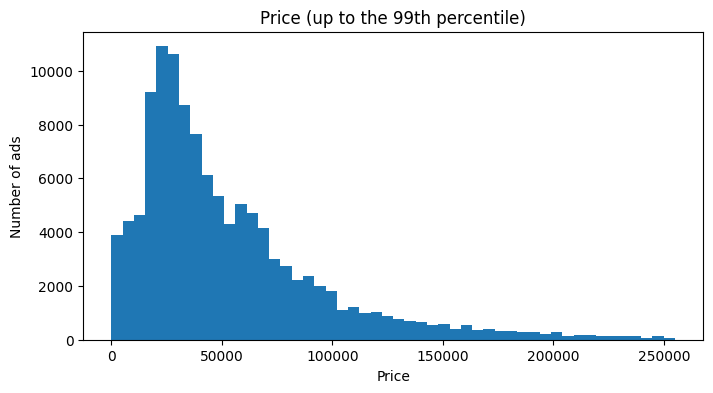

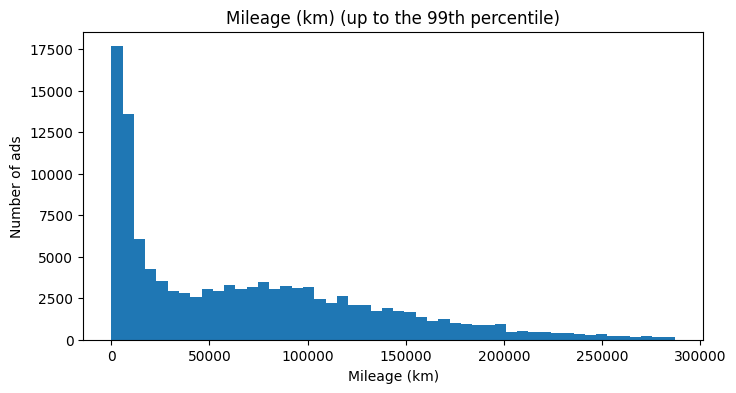

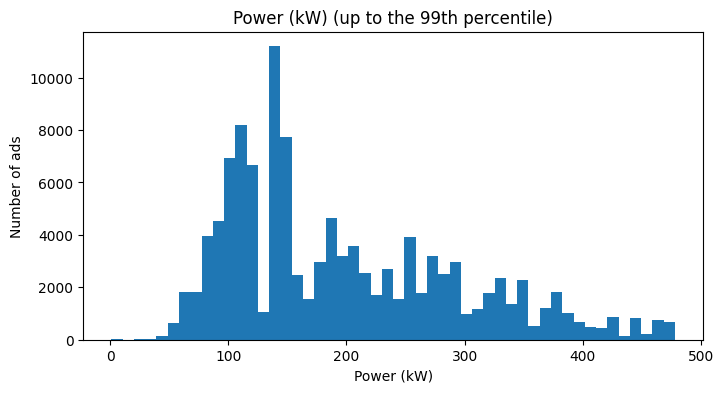

In [19]:
# Draw a histogram
# We cut at the 99th percentile only for the PLOT, otherwise a few huge
# values flatten everything else.
def draw_histogram(series, title, file_name):
    values = series.dropna()
    limit = values.quantile(0.99)
    reduced_values = values[values <= limit]

    plt.figure(figsize=(8, 4))
    plt.hist(reduced_values, bins=50)
    plt.title(title + " (up to the 99th percentile)")
    plt.xlabel(title)
    plt.ylabel("Number of ads")
    plt.savefig(FIGURES_FOLDER + "/" + file_name, dpi=150, bbox_inches="tight")
    plt.show()

draw_histogram(df["price"], "Price", "audit_price.png")
draw_histogram(df["mileage_km_raw"], "Mileage (km)", "audit_km.png")
draw_histogram(df["power_kw"], "Power (kW)", "audit_power.png")

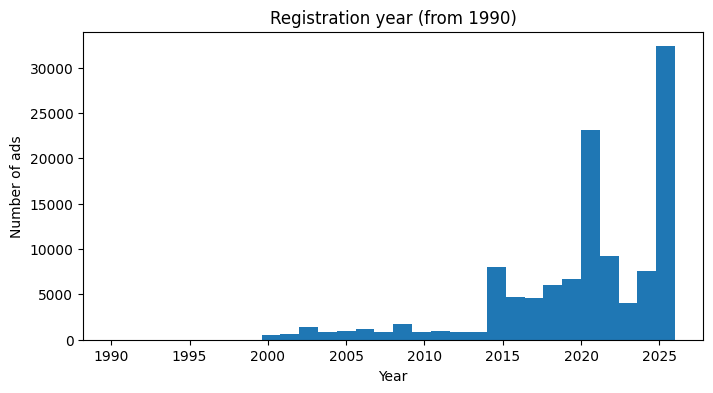

In [20]:
years = reg_year.dropna()
years = years[years >= 1990]

plt.figure(figsize=(8, 4))
plt.hist(years, bins=30)
plt.title("Registration year (from 1990)")
plt.xlabel("Year")
plt.ylabel("Number of ads")
plt.savefig(FIGURES_FOLDER + "/audit_registration_year.png", dpi=150, bbox_inches="tight")
plt.show()

### 1.7. Choice of the training set

Two options:
- **A. Italy only**: consistent with the target market; prices are not mixed between different countries.
- **B. All countries** with `country_code` as a feature, and separate evaluation on Italy: more data, but the model must learn that the markets are different.

Let's look at the numbers before deciding.

In [21]:
essential_columns = ["make", "model", "registration_date", "mileage_km_raw", "price"]

complete_italy = italian_rows[essential_columns].dropna()
all_complete = df[essential_columns].dropna()

print("Total Italian rows:             ", len(italian_rows))
print("Italian rows with essential data:", len(complete_italy))
print("Total rows with essential data:  ", len(all_complete))

Total Italian rows:              23957
Italian rows with essential data: 23889
Total rows with essential data:   116228


In [22]:
print("Top 10 makes in Italy:")
print(italian_rows["make"].value_counts().head(10))
print()

model_count = italian_rows["model"].value_counts()

RARE_MODEL_THRESHOLD = 30   # below this number of ads the model is "rare"
rare_models = (model_count < RARE_MODEL_THRESHOLD).sum()

print("Distinct models in Italy:", len(model_count))
print("Models with less than", RARE_MODEL_THRESHOLD, "ads:", rare_models)

Top 10 makes in Italy:
make
Porsche          6606
BMW              5999
Alfa Romeo       4878
Audi             3193
Suzuki            917
Mercedes-Benz     907
Volvo             614
Maserati          141
Honda             132
smart             119
Name: count, dtype: int64

Distinct models in Italy: 429
Models with less than 30 ads: 330


In [23]:
# 1. Does the median and mean price change a lot from one country to another?
prices_per_country = df.groupby("country_code")["price"].agg(["count", "median", "mean"]).round(0)
prices_per_country = prices_per_country.sort_values("count", ascending=False)

print("Comparison of prices (in EUR) by Country:")
display(prices_per_country)

# 2. How many ads fall into "rare" models (< 30 ads) in Italy vs Europe?
rare_model_names_it = model_count[model_count < RARE_MODEL_THRESHOLD].index
ads_in_rare_models_it = italian_rows["model"].isin(rare_model_names_it).sum()

model_count_eu = df["model"].value_counts()
rare_model_names_eu = model_count_eu[model_count_eu < RARE_MODEL_THRESHOLD].index
ads_in_rare_models_eu = df["model"].isin(rare_model_names_eu).sum()

print(f"\nItalian ads in rare models (<{RARE_MODEL_THRESHOLD} ads in IT): "
      f"{ads_in_rare_models_it} ({percentage(ads_in_rare_models_it, n_italy)}%)")
print(f"European ads in rare models (<{RARE_MODEL_THRESHOLD} ads in EU): "
      f"{ads_in_rare_models_eu} ({percentage(ads_in_rare_models_eu, total_rows)}%)")

Comparison of prices (in EUR) by Country:


,count,median,mean
country_code,,,
DE,45611,42950.0,58031.0
IT,23957,32900.0,53162.0
NL,17059,47950.0,61287.0
BE,9582,35470.0,51488.0
ES,8015,34500.0,53512.0
AT,7213,42500.0,59397.0
FR,6141,49990.0,70464.0
LU,789,59990.0,74067.0



Italian ads in rare models (<30 ads in IT): 2229 (9.3%)
European ads in rare models (<30 ads in EU): 2364 (2.0%)


In [24]:
# Possible values: "italy_only" or "all_countries"
TRAINING_CHOICE = "italy_only"

if TRAINING_CHOICE == "italy_only":
    chosen_df = df[df["country_code"] == "IT"]
else:
    chosen_df = df

print("Choice:", TRAINING_CHOICE)
print("Rows in the chosen training set:", len(chosen_df))

Choice: italy_only
Rows in the chosen training set: 23957


### 1.8. Exclusion of columns with personal or identifying data

These columns **do not enter the model data**:
- due to GDPR (street, zip, seller company name are sellers' data)
- to avoid *leakage* (`id`, `vin` and `description` might allow the model to "recognize" the ad)

Attention: `id` and `vin` are still needed to remove duplicates and perform the split
without putting the same ad in both train and test. So we save them **in a separate file**,
which will never be used as model input.

In [25]:
columns_to_exclude = ["id", "vin", "street", "zip", "seller_company_name",
                        "description", "city", "latitude", "longitude"]

present_columns_to_exclude = []
for name in columns_to_exclude:
    if name in chosen_df.columns:
        present_columns_to_exclude.append(name)

print("Columns excluded from model data:", present_columns_to_exclude)

# Separate file with only the keys (needed only for duplicates and split)
keys = chosen_df[["id", "vin"]]

# Data for the model: without the excluded columns
model_df = chosen_df.drop(columns=present_columns_to_exclude)

print("Rows:", model_df.shape[0], "Columns:", model_df.shape[1])

Columns excluded from model data: ['id', 'vin', 'street', 'zip', 'seller_company_name', 'description', 'city', 'latitude', 'longitude']
Rows: 23957 Columns: 66


In [26]:
for name in model_df.columns:
    print(name)

ratings_average
ratings_count
ratings_recommend_percentage
price_currency
price
price_tax_deductible
price_negotiable
price_net
price_vat_rate
make
model
model_version
german_hsn_tsn
mileage_km_raw
mileage_km
registration_date
production_year
vehicle_type
body_type
nr_seats
nr_doors
body_color
paint_type
body_color_original
upholstery
upholstery_color
power_kw
power_hp
transmission
gears
drive_train
cylinders
cylinders_volume_cc
weight_kg
has_particle_filter
fuel_category
primary_fuel
electric_range_km
electric_range_city_km
fuel_cons_comb_l100_km
fuel_cons_city_l100_km
fuel_cons_highway_l100_km
co2_emission_grper_km
fuel_cons_comb_l100_wltp_km
fuel_cons_electric_comb_l100_wltp_km
co2_emission_grper_wltp_km
equipment_comfort
equipment_entertainment
equipment_extra
equipment_safety
is_used
is_new
is_preregistered
had_accident
has_full_service_history
non_smoking
nr_prev_owners
is_rental
envir_standard
original_market
offer_type
country_code
seller_is_dealer
seller_type
has_warranty
warr

In [27]:
model_df.to_csv(DATA_FOLDER + "/model_dataset.csv", index_label="original_row")
keys.to_csv(DATA_FOLDER + "/ad_keys.csv", index_label="original_row")

print("Saved: model_dataset.csv and ad_keys.csv")

Saved: model_dataset.csv and ad_keys.csv


### 1.9. Final summary table of quality issues

In [28]:
issues_table = pd.DataFrame(issues)
issues_table = issues_table.sort_values("percentage_of_total", ascending=False)
issues_table.to_csv(AUDIT_FOLDER + "/quality_issues.csv", index=False)

print("=== QUALITY ISSUES ON THE ENTIRE DATASET (118,382 rows) ===")
display(issues_table)

# Specific summary on the chosen subset (Italy)
it_reg_date = pd.to_datetime(italian_rows["registration_date"], errors="coerce")
italy_summary = pd.DataFrame([
    {"check": "Total rows Italy", "rows": n_italy, "perc_italy": 100.0},
    {"check": "Records without essential data (make, model, date, km, price)",
     "rows": n_italy - len(complete_italy), "perc_italy": percentage(n_italy - len(complete_italy), n_italy)},
    {"check": "Missing VINs",
     "rows": int(italian_rows["vin"].isna().sum()), "perc_italy": percentage(italian_rows["vin"].isna().sum(), n_italy)},
    {"check": "Repeated VINs (excluding missing)",
     "rows": int(italian_rows["vin"].dropna().duplicated().sum()), "perc_italy": percentage(italian_rows["vin"].dropna().duplicated().sum(), n_italy)},
    {"check": f"Price below {LOW_PRICE_THRESHOLD} EUR",
     "rows": int((italian_rows["price"] < LOW_PRICE_THRESHOLD).sum()), "perc_italy": percentage((italian_rows["price"] < LOW_PRICE_THRESHOLD).sum(), n_italy)},
    {"check": f"Power above {HIGH_POWER_THRESHOLD_KW} kW",
     "rows": int((italian_rows["power_kw"] > HIGH_POWER_THRESHOLD_KW).sum()), "perc_italy": percentage((italian_rows["power_kw"] > HIGH_POWER_THRESHOLD_KW).sum(), n_italy)},
    {"check": "Registration in the future (beyond today)",
     "rows": int((it_reg_date > today).sum()), "perc_italy": percentage((it_reg_date > today).sum(), n_italy)},
])
italy_summary.to_csv(AUDIT_FOLDER + "/quality_issues_italy.csv", index=False)

print("\n=== ISSUES SUMMARY ON ITALY PERIMETER (23,957 rows) ===")
display(italy_summary)

=== QUALITY ISSUES ON THE ENTIRE DATASET (118,382 rows) ===


,category,description,involved_rows,percentage_of_total
1,missing values,column fuel_cons_highway_l100_km with at least 20% missing,118382,100.00
3,missing values,column warranty with at least 20% missing,118382,100.00
2,missing values,column has_warranty with at least 20% missing,118382,100.00
4,missing values,column fuel_cons_city_l100_km with at least 20% missing,118382,100.00
5,missing values,column electric_range_city_km with at least 20% missing,117743,99.46
35,data type,mileage_km is text (numerical mileage_km_raw exists),117738,99.46
6,missing values,column fuel_cons_electric_comb_l100_wltp_km with at least 20% missing,113456,95.84
7,missing values,column electric_range_km with at least 20% missing,105637,89.23
8,missing values,column production_year with at least 20% missing,96110,81.19
36,data type,"weight_kg is text (e.g. 1,945 kg)",94296,79.65



=== ISSUES SUMMARY ON ITALY PERIMETER (23,957 rows) ===


,check,rows,perc_italy
0,Total rows Italy,23957,100.00
1,"Records without essential data (make, model, date, km, price)",68,0.28
2,Missing VINs,16860,70.38
3,Repeated VINs (excluding missing),768,3.21
4,Price below 500 EUR,7,0.03
5,Power above 1000 kW,15,0.06
6,Registration in the future (beyond today),0,0.00


## 2. Preprocessing
**Goal:** Define and execute preprocessing pipeline on the dataset. Explore dataset, analyzing its features and the distribution of values throughout rows. Every data manipulation performed to obtain training and test sets are deeply documented here.

### 2.1. Defining preprocessing

#### 2.1.1. Column parameters and roles

All design choices are gathered in this single cell, so they are easily visible and editable.

| Parameter | Meaning |
|---|---|
| `REFERENCE_YEAR` | Year to which the dataset snapshot refers: needed to calculate age |
| `*_THRESHOLD` | Fixed thresholds for flags (low price, high power, very high km) |
| `*_GROSS_NET_RATIO` | Plausible range of `price / price_net` (VAT) |
| `TOO_EMPTY_COLUMN_THRESHOLD` | Beyond this % of missing values (on training) a numerical column is not imputed |

**P.S.:** Before the split we only use fixed thresholds. Thresholds derived from data (percentiles) are calculated later, only on the training set.

In [29]:
REFERENCE_YEAR = 2025

LOW_PRICE_THRESHOLD = 500        
HIGH_POWER_KW_THRESHOLD = 1000    
HIGH_KM_THRESHOLD = 1000000

MIN_GROSS_NET_RATIO = 1.0
MAX_GROSS_NET_RATIO = 1.3

TOO_EMPTY_COLUMN_THRESHOLD = 60


# --- Column roles ---
# Without this data an ad is not usable
ESSENTIAL_COLUMNS = ["make", "model", "registration_date", "mileage_km", "price"]

# Columns excluded from the model (with the reason of the exclusion)
PRICE_LEAKAGE_COLUMNS = ["price_net", "price_vat_rate"]                                 # derived from price
SELLER_COLUMNS = ["ratings_average", "ratings_count", "ratings_recommend_percentage"]   # they talk about the seller, not the car
FREE_TEXT_COLUMNS = ["model_version", "body_color_original", "german_hsn_tsn"]          # free text / codes / too many distinct values
REDUNDANT_COLUMNS = ["production_year", "price_currency"]                               # 81% missing / always EUR

# Lists written as text
EQUIPMENT_COLUMNS = ["equipment_comfort", "equipment_entertainment",
                     "equipment_extra", "equipment_safety"]

# Columns to impute
NUMERICAL_COLUMNS = ["power_kw", "power_hp", "nr_seats", "nr_doors", "gears", "cylinders",
                     "cylinders_volume_cc", "weight_kg", "nr_prev_owners", "electric_range_km",
                     "electric_range_city_km", "fuel_cons_comb_l100_km",
                     "fuel_cons_comb_l100_wltp_km", "fuel_cons_electric_comb_l100_wltp_km",
                     "co2_emission_grper_km", "co2_emission_grper_wltp_km"]
CATEGORICAL_COLUMNS = ["vehicle_type", "body_type", "body_color", "paint_type", "upholstery",
                       "upholstery_color", "transmission", "drive_train", "fuel_category",
                       "primary_fuel", "envir_standard", "original_market", "offer_type",
                       "country_code", "seller_type"]

#### 2.1.2. Cleaning functions: text, types, log

* **`log_step`**: every time rows are removed, it writes how many there were before and after, both on screen and in the `cleaning_log` list. In the end it becomes `cleaning_log.csv` and it is the "how many rows we lose and why" table for the paper.
* **`only_present_columns`**: filters a list of names keeping only those that exist in the DataFrame (prevents errors if a column has already been removed).
* **`normalize_text`**: lowercase, no trailing spaces, only one space between words. `"BMW "` and `"bmw"` become the same make.
* **`convert_types`**: keeps `mileage_km_raw` (numerical) renaming it `mileage_km` and discards the text version (`"10,500 km"`); converts `weight_kg` (`"1,945 kg"`) to number; converts the date and extracts the year.

In [30]:
cleaning_log = []

def log_step(step_name, rows_before, rows_after):
    row = {
        "step": step_name,
        "rows_before": rows_before,
        "rows_after": rows_after,
        "removed_rows": rows_before - rows_after,
    }
    cleaning_log.append(row)
    print(f"{step_name}: {rows_before} -> {rows_after} rows (removed: {rows_before - rows_after})")

def only_present_columns(df, column_list):
    present = []
    for name in column_list:
        if name in df.columns:
            present.append(name)
    return present

def normalize_text(text):
    if pd.isna(text):
        return text
    words = str(text).strip().lower().split()   
    if len(words) == 0:
        return np.nan                              # empty string = missing
    return " ".join(words)

def normalize_make_model(df):
    df = df.copy()
    df["make"] = df["make"].apply(normalize_text)
    df["model"] = df["model"].apply(normalize_text)
    return df

def weight_to_number(text):
    # "1,945 kg" -> 1945
    if pd.isna(text):
        return np.nan
    cleaned = str(text).replace("kg", "").replace(",", "").strip()
    return pd.to_numeric(cleaned, errors="coerce")

def convert_types(df):
    df = df.copy()
    df = df.drop(columns=["mileage_km"])                           # text version
    df = df.rename(columns={"mileage_km_raw": "mileage_km"})       # numerical version
    df["weight_kg"] = df["weight_kg"].apply(weight_to_number)
    df["registration_date"] = pd.to_datetime(df["registration_date"], errors="coerce")
    df["registration_year"] = df["registration_date"].dt.year
    return df

#### 2.1.3. Quality flags

We mark suspicious rows: each flag is a `True/False` column, and the number of flagged rows ends up in the table for the paper.

| Flag | Turns on when |
|---|---|
| `low_price_flag` | price below `LOW_PRICE_THRESHOLD` |
| `high_power_flag` | `power_kw` above `HIGH_POWER_THRESHOLD_KW` |
| `very_high_km_flag` | km above `HIGH_KM_THRESHOLD` |
| `year_beyond_reference_flag` | registration year after `REFERENCE_YEAR` |
| `new_and_used_flag` | `is_new` and `is_used` both true |
| `inconsistent_price_net_flag` | `price / price_net` outside the plausible range (gross price check) |
| `invalid_vin_flag` | VIN present but invalid (length, characters, placeholder) |

A comparison with a missing value always yields `False`: a row without `price_net` is not flagged by the gross/net check.

`valid_vin` is instead a utility column, used for duplicates.

In [31]:
def valid_vin(vin):
    # A VIN is valid if it has 17 characters, does not contain I, O, Q
    # and is not a placeholder (e.g. 00000000000000000: a single repeated character)
    if pd.isna(vin):
        return False
    vin = str(vin).strip().upper()
    if len(vin) != 17:
        return False
    for character in vin:
        if character in "IOQ" or not character.isalnum():
            return False
    if len(set(vin)) == 1:            # set = distinct characters; if there is only one it's a placeholder
        return False
    return True

def add_quality_flags(df):
    df = df.copy()
    df["low_price_flag"] = df["price"] < LOW_PRICE_THRESHOLD
    df["high_power_flag"] = df["power_kw"] > HIGH_POWER_THRESHOLD_KW
    df["very_high_km_flag"] = df["mileage_km"] > HIGH_KM_THRESHOLD
    df["year_beyond_reference_flag"] = df["registration_year"] > REFERENCE_YEAR
    df["new_and_used_flag"] = df["is_new"] & df["is_used"]

    ratio = df["price"] / df["price_net"]
    out_of_range = (ratio < MIN_GROSS_NET_RATIO) | (ratio > MAX_GROSS_NET_RATIO)
    df["inconsistent_price_net_flag"] = out_of_range

    df["valid_vin"] = df["vin"].apply(valid_vin)
    df["invalid_vin_flag"] = df["vin"].notna() & ~df["valid_vin"]
    return df

def flags_table(df):
    rows = []
    for name in df.columns:
        if name.startswith("flag_") or name.endswith("_flag"):
            quantity = int(df[name].sum())
            rows.append({"flag": name, "rows": quantity,
                          "percentage": round(quantity / len(df) * 100, 2)})
    return pd.DataFrame(rows)

#### 2.1.4. Excluded columns, incomplete records, duplicates, missing fields

* **`remove_useless_columns`**: removes completely empty columns plus the lists decided in the parameters (leakage, seller, free text, redundant).
* **`remove_without_essential_data`**: removes records missing make, model, registration year, mileage or price.
* **`add_n_missing_fields`**: number of missing values per row, calculated **before** imputation (afterwards it would no longer make sense). Serves both as a feature and to choose which duplicate to keep.
* **`remove_duplicates`**: two steps.
  1. Same **valid VIN** = same car: we keep the most complete ad (fewer missing fields). Missing or placeholder VINs are not touched.
  2. Same **composite key** (make, model, date, km, power, price): covers ads without VIN (66% of the dataset).

After this step no valid VIN appears twice.

In [32]:
def remove_useless_columns(df):
    df = df.copy()
    to_remove = []

    # 1) completely empty columns
    for name in df.columns:
        if df[name].isna().all():
            to_remove.append(name)

    # 2) manually decided columns
    decided_lists = PRICE_LEAKAGE_COLUMNS + SELLER_COLUMNS + FREE_TEXT_COLUMNS + REDUNDANT_COLUMNS
    for name in decided_lists:
        if name in df.columns and name not in to_remove:
            to_remove.append(name)

    print("Removed columns:", to_remove)
    return df.drop(columns=to_remove)

def remove_without_essential_data(df):
    rows_before = len(df)
    df = df.dropna(subset=ESSENTIAL_COLUMNS)
    df = df[(df["price"] > 0) & (df["mileage_km"] >= 0)]
    log_step("Records without make, model, year, km or price (or with values <= 0)", rows_before, len(df))
    return df

def add_n_missing_fields(df):
    df = df.copy()
    columns = only_present_columns(df, NUMERICAL_COLUMNS + CATEGORICAL_COLUMNS)
    df["n_missing_fields"] = df[columns].isna().sum(axis=1)     # axis=1: sum per row
    return df

def create_ad_key(df):
    parts = [df["make"], df["model"], df["registration_date"], df["mileage_km"], df["power_kw"], df["price"]]
    parts = [p.astype(str).fillna("missing") for p in parts]
    return parts[0].str.cat(parts[1:], sep="|")

def remove_duplicates(df):
    # Most complete rows first, so drop_duplicates keeps the best copy.
    # A stable sort makes the result reproducible.
    df = df.sort_values("n_missing_fields", kind="mergesort")

    # Step 1: same VIN
    rows_before = len(df)
    with_vin = df[df["valid_vin"]]
    without_vin = df[~df["valid_vin"]]
    with_vin = with_vin.drop_duplicates(subset=["vin"], keep="first")
    df = pd.concat([with_vin, without_vin])
    log_step("Duplicates: same valid VIN", rows_before, len(df))

    # Step 2: same compound key (make, model, date, km, power, price)
    rows_before = len(df)
    df["ad_key"] = create_ad_key(df)
    df = df.drop_duplicates(subset=["ad_key"], keep="first")
    log_step("Duplicates: same ad_key (make, model, date, km, power, price)", rows_before, len(df))

    df = df.drop(columns=["ad_key"])
    return df.sort_index()      # Restore original order

#### 2.1.5. Feature engineering

| Feature | Definition |
|---|---|
| `car_age` | `REFERENCE_YEAR - registration_year` (minimum 0) |
| `km_per_year` | `mileage_km / max(car_age, 1)`: avoids division by zero for new cars |
| `n_equipment_*`, `n_optional` | number of elements in each `equipment_*` list and total. The lists are written as text (`"['Radio', 'Spoiler']"`): `ast.literal_eval` transforms them into real lists and `len` counts them |
| `n_missing_fields` | already calculated above |
| `log_price` | `log(price)`: target variable of the model |

`price`, `price / age` and similar will **not** enter among the features of the model: they are only needed as targets or later on.

In [33]:
def count_options(text):
    if pd.isna(text):
        return 0
    try:
        element_list = ast.literal_eval(text)
        return len(element_list)
    except (ValueError, SyntaxError):
        return 0

def add_features(df):
    df = df.copy()
    
    # For pure electric cars, missing cylinders and displacement are 0
    electric_mask = df["fuel_category"].astype(str).str.lower() == "electric"
    if "cylinders" in df.columns:
        df.loc[electric_mask & df["cylinders"].isna(), "cylinders"] = 0.0
    if "cylinders_volume_cc" in df.columns:
        df.loc[electric_mask & df["cylinders_volume_cc"].isna(), "cylinders_volume_cc"] = 0.0

    df["car_age"] = (REFERENCE_YEAR - df["registration_year"]).clip(lower=0)
    df["km_per_year"] = df["mileage_km"] / np.maximum(df["car_age"], 1)

    df["n_options"] = 0
    for name in EQUIPMENT_COLUMNS:
        if name in df.columns:
            count = df[name].apply(count_options)
            df["n_" + name] = count
            df["n_options"] = df["n_options"] + count

    df["log_price"] = np.log(df["price"])
    
    # We remove the raw text columns already transformed into numerical features
    raw_columns_to_remove = only_present_columns(df, EQUIPMENT_COLUMNS + ["registration_date"])
    df = df.drop(columns=raw_columns_to_remove)
    
    return df

#### 2.1.6. Split and imputation

* **`split_train_test`**: 80/20 split with fixed `SEED`.
* **`check_shared_vins`**: checks that no valid VIN is in both train and test (must give 0).
* **`remove_identifiers`**: after the check, `vin` is permanently removed from the data.
* **`calculate_imputation_parameters`**: medians of numerical columns, calculated **only on training**. A numerical column with too many missing values (over `THRESHOLD_TOO_EMPTY_COLUMN`) is not imputed, because a median would not make sense (e.g. electric range for petrol cars) and remains with `NaN`. For categoricals the value is always `"unknown"`.
* **`apply_imputation`**: applies the same parameters to train and test. The parameters are saved in a JSON file.

In [34]:
def split_train_test(df):
    train, test = train_test_split(df, test_size=TEST_SHARE, random_state=SEED)
    train = train.reset_index(drop=True)
    test = test.reset_index(drop=True)
    return train, test

def check_shared_vins(train, test):
    train_vin = train.loc[train["valid_vin"], "vin"]
    test_vin = test.loc[test["valid_vin"], "vin"]
    n_shared = test_vin.isin(train_vin).sum()
    print("Valid VINs present in both train and test:", n_shared)
    return n_shared

def remove_identifiers(df):
    return df.drop(columns=["id", "vin", "valid_vin"])

def calculate_imputation_parameters(train):
    medians = {}
    not_imputed = []
    for name in only_present_columns(train, NUMERICAL_COLUMNS):
        missing_percentage = train[name].isna().mean() * 100
        if missing_percentage > TOO_EMPTY_COLUMN_THRESHOLD:
            not_imputed.append(name)
        else:
            medians[name] = float(train[name].median())
    categoricals = only_present_columns(train, CATEGORICAL_COLUMNS)
    return {"medians": medians, "categoricals": categoricals, "not_imputed": not_imputed}

def apply_imputation(df, parameters):
    df = df.copy()
    for name, median in parameters["medians"].items():
        df[name] = df[name].fillna(median)
    for name in parameters["categoricals"]:
        df[name] = df[name].fillna("unknown")
    return df

#### 2.1.7. Baseline models and metrics

**Baseline 1: median by make, model and year.** For each test car, the median of the training prices with the same make, model and year is taken. If that combination does not exist in the training, we go down to make+model, then to just the make, then to the global median.

**Baseline 2: linear regression on log(price).** Features: age, log(km), log(HP), number of options and dummy variables for make, fuel, transmission and bodywork. The forecast is reported in euros with `exp`.

**Metrics** (all on the test, in euros):
* `MAE`: mean absolute error.
* `MAPE`: mean absolute percentage error.
* `MdAPE`: median absolute percentage error, robust to outliers.

`MAPE` explodes with ridiculous prices: if an ad costs 1 euro and the model predicts 20,000, the percentage error is 2,000,000%. For this reason the table also shows the results **without the rows with `low_price_flag`**.

In [35]:
def calculate_metrics(actual, predicted):
    absolute_error = np.abs(actual - predicted)
    percentage_error = absolute_error / actual * 100
    return {
        "MAE_euros": np.mean(absolute_error),
        "MAPE_%": np.mean(percentage_error),
        "MdAPE_%": np.median(percentage_error),
    }

def evaluate_model(name, test, predicted_price):
    actual = test["price"].values
    without_suspicious = ~test["low_price_flag"].values      # True for UNflagged rows
    all_rows = calculate_metrics(actual, predicted_price)
    clean_rows = calculate_metrics(actual[without_suspicious], predicted_price[without_suspicious])
    return {
        "model": name,
        "MAE_euros": round(all_rows["MAE_euros"], 0),
        "MAPE_%": round(all_rows["MAPE_%"], 1),
        "MdAPE_%": round(all_rows["MdAPE_%"], 1),
        "MAE_euros_without_suspicious_prices": round(clean_rows["MAE_euros"], 0),
        "MAPE_%_without_suspicious_prices": round(clean_rows["MAPE_%"], 1),
    }

def median_baseline(train, test):
    keys_3 = ["make", "model", "registration_year"]
    keys_2 = ["make", "model"]
    keys_1 = ["make"]

    med_3 = train.groupby(keys_3)["price"].median().reset_index().rename(columns={"price": "pred_3"})
    med_2 = train.groupby(keys_2)["price"].median().reset_index().rename(columns={"price": "pred_2"})
    med_1 = train.groupby(keys_1)["price"].median().reset_index().rename(columns={"price": "pred_1"})

    result = test[keys_3].copy()
    result = result.merge(med_3, on=keys_3, how="left")
    result = result.merge(med_2, on=keys_2, how="left")
    result = result.merge(med_1, on=keys_1, how="left")

    # Where the most precise prediction is missing, the next one is used
    prediction = result["pred_3"].fillna(result["pred_2"])
    prediction = prediction.fillna(result["pred_1"])
    prediction = prediction.fillna(train["price"].median())
    return prediction.values


def prepare_linear_matrix(df):
    X = pd.DataFrame()
    X["car_age"] = df["car_age"]
    X["log_km"] = np.log1p(df["mileage_km"])
    X["log_power"] = np.log1p(df["power_hp"])
    X["n_options"] = df["n_options"]

    categoricals = df[["fuel_category", "transmission", "body_type"]].copy()
    categoricals["make_model"] = df["make"] + " " + df["model"]    # make and model together
    dummies = pd.get_dummies(categoricals, dtype=float)
    return pd.concat([X, dummies], axis=1)

### 2.2. Executing preprocessing

#### 2.2.1. Loading and joining the two tables

In [36]:
cleaning_log = []   

model_data = pd.read_csv(DATASET_FILE, low_memory=False)
file_keys = pd.read_csv(KEYS_FILE)

# We join data and keys (id, vin) through the line number of the original CSV
data = model_data.merge(file_keys, on="original_row", how="left")

print("Rows model_data: ", len(model_data))
print("Rows after union:", len(data))  # must be equal

Rows model_data:  23957
Rows after union: 23957


#### 2.2.2. Normalization, types and reference year check

The age of the car is calculated with respect to the year the dataset was created (2025, as it stands on [Kaggle](https://www.kaggle.com/datasets/clkmuhammed/autoscout24-car-listings-dataset)), **not with respect to today**.

In [37]:
print("Distinct makes before:", data["make"].nunique(), "| Distinct models before:", data["model"].nunique())

data = normalize_make_model(data)
print("Distinct makes after: ", data["make"].nunique(), "| Distinct models after: ", data["model"].nunique())

data = convert_types(data)

# Reference year check
print()
print("Latest registration date:", data["registration_date"].max())
print(data["registration_year"].value_counts().sort_index().tail(5))

Distinct makes before: 25 | Distinct models before: 429
Distinct makes after:  25 | Distinct models after:  429

Latest registration date: 2026-11-01 00:00:00
registration_year
2022.0    1794
2023.0    1490
2024.0    2002
2025.0    3570
2026.0      19
Name: count, dtype: int64


#### 2.2.3. Gross price and VIN check

Before removing `price_net` we verify that the price is gross: the ratio `price / price_net` should correspond to VAT (about 1.19-1.22).

In [38]:
data = add_quality_flags(data)

# Gross price check: price / net price ratio
ratio = data["price"] / data["price_net"]
print(ratio.describe())
print()
print(ratio.round(2).value_counts().head(10))

# VIN check
print()
print("Most frequent:")
print(data["vin"].value_counts().head(5))
print("Valid VINs:", data["valid_vin"].sum(),
      "| Present but not valid:", data["invalid_vin_flag"].sum(),
      "| Missing:", data["vin"].isna().sum())

count    702.00
mean       1.62
std        1.49
min        1.00
25%        1.00
50%        1.00
75%        1.22
max        5.55
dtype: float64

1.00    461
1.22    113
5.55     88
1.28     25
1.19      5
1.18      2
1.23      2
1.25      2
1.27      1
1.21      1
Name: count, dtype: int64

Most frequent:
vin
00000000000000000    67
11111111111111111    22
XXXXXXXXXXXXXXXXX     9
WAUZZZF38M1032792     8
ZARNASAS8N3023522     7
Name: count, dtype: int64
Valid VINs: 6881 | Present but not valid: 216 | Missing: 16860


Let's look at the three groups of the `price / price_net` ratio and compare the median prices: if the 5.55 group has normal prices, the anomaly is in the net price and not in the asking price.

In [39]:
check_df = model_data[["price", "price_net", "price_vat_rate", "price_tax_deductible", "make", "model"]].copy()
check_df = check_df.dropna(subset=["price_net"])
check_df["ratio"] = (check_df["price"] / check_df["price_net"]).round(2)

check_df["group"] = "between 1.01 and 1.30"
check_df.loc[check_df["ratio"] == 1.00, "group"] = "equal to 1.00"
check_df.loc[check_df["ratio"] > 1.30, "group"] = "over 1.30"

print(check_df["group"].value_counts())
print()
print(pd.crosstab(check_df["group"], check_df["price_tax_deductible"]))
print()
print("Median price by group:")
print(check_df.groupby("group")["price"].median())
print()
print(check_df[check_df["group"] == "over 1.30"].head(10))

group_88 = check_df[check_df["group"] == "over 1.30"].copy()
expected_vat = group_88["price"] - group_88["price"] / 1.22
difference = (group_88["price_net"] - expected_vat).abs()

print("Rows where price_net coincides with the VAT amount (±2 euros):",
      (difference <= 2).sum(), "su", len(group_88))

group
equal to 1.00            461
between 1.01 and 1.30    153
over 1.30                 88
Name: count, dtype: int64

price_tax_deductible   False  True 
group                              
between 1.01 and 1.30      0    153
equal to 1.00            387     74
over 1.30                  0     88

Median price by group:
group
between 1.01 and 1.30    39490.0
equal to 1.00            27750.0
over 1.30                51000.0
Name: price, dtype: float64

         price  price_net  price_vat_rate  price_tax_deductible        make  \
263    49900.0     8998.0             0.0                  True     Porsche   
402    23500.0     4237.0             NaN                  True         BMW   
864    28900.0     5211.0             0.0                  True  Alfa Romeo   
963    43900.0     7916.0             0.0                  True     Porsche   
999   249000.0    44901.0             0.0                  True     Porsche   
1032   20900.0     3768.0             0.0                  True     

In the "over 1.30" group, the anomalously high `price` / `price_net` ratio (approximately $5.55$) reveals a systematic data entry error. Instead of recording the actual net price in the `price_net` column, the operator mistakenly inputted the VAT amount (the tax value itself). For example, on a $€49,900$ vehicle with a standard $22\%$ VAT rate, the tax amounts to exactly $€8,998$ (which perfectly matches the value found in the `price_net` field for that specific entry). Consequently, while the gross `price` is correct and reliable, the `price_net` values for these 88 records are corrupted and must be recalculated to reflect the true taxable amount.

#### 2.2.4. Columns, incomplete records, duplicates
Removing useless columns, incomplete rows and duplicates from the dataset.

In [40]:
data = remove_useless_columns(data)
print()
data = remove_without_essential_data(data)
data = add_n_missing_fields(data)
data = remove_duplicates(data)
data = add_features(data)

print()
print("Final rows:", len(data), "| Columns:", data.shape[1])

print("\nCheck uniqueness of remaining valid VINs (first 3 occurrences):")
print(data.loc[data["valid_vin"], "vin"].value_counts().head(3))

flag_df = flags_table(data)
flag_df.to_csv(AUDIT_FOLDER + "/quality_flags.csv", index=False)
print("\nSummary table of quality flags:")
display(flag_df)

Removed columns: ['fuel_cons_city_l100_km', 'fuel_cons_highway_l100_km', 'has_warranty', 'warranty', 'price_net', 'price_vat_rate', 'ratings_average', 'ratings_count', 'ratings_recommend_percentage', 'model_version', 'body_color_original', 'german_hsn_tsn', 'production_year', 'price_currency']

Records without make, model, year, km or price (or with values <= 0): 23957 -> 23889 rows (removed: 68)
Duplicates: same valid VIN: 23889 -> 23242 rows (removed: 647)
Duplicates: same ad_key (make, model, date, km, power, price): 23242 -> 22632 rows (removed: 610)

Final rows: 22632 | Columns: 67

Check uniqueness of remaining valid VINs (first 3 occurrences):
vin
ZAA5AVAT4RJA31506    1
WP0ZZZY13SSA60220    1
WAUZZZF20SN051902    1
Name: count, dtype: int64

Summary table of quality flags:


,flag,rows,percentage
0,low_price_flag,7,0.03
1,high_power_flag,15,0.07
2,very_high_km_flag,1,0.00
3,year_beyond_reference_flag,11,0.05
4,new_and_used_flag,0,0.00
5,inconsistent_price_net_flag,75,0.33
6,invalid_vin_flag,207,0.91


#### 2.2.5. Split, imputation, saving

In [41]:
train, test = split_train_test(data)
print("Train:", len(train), "| Test:", len(test))
check_shared_vins(train, test)    

train = remove_identifiers(train)
test = remove_identifiers(test)

# Copy with original missing values
train_with_missing = train.copy()
test_with_missing = test.copy()

# Parameters calculated ONLY on training
parameters = calculate_imputation_parameters(train)
print("Numerical columns NOT imputed (too many missing values):", parameters["not_imputed"])

train = apply_imputation(train, parameters)
test = apply_imputation(test, parameters)

print("Median price train:", train["price"].median(), "| Test:", test["price"].median())

with open(DATA_FOLDER + "/imputation_parameters.json", "w", encoding="utf-8") as f:
    json.dump(parameters, f, indent=2)
train.to_csv(DATA_FOLDER + "/clean_train.csv", index=False)
test.to_csv(DATA_FOLDER + "/clean_test.csv", index=False)
train_with_missing.to_csv(DATA_FOLDER + "/train_with_missing.csv", index=False)
test_with_missing.to_csv(DATA_FOLDER + "/test_with_missing.csv", index=False)

log_table = pd.DataFrame(cleaning_log)
log_table.to_csv(AUDIT_FOLDER + "/cleaning_log.csv", index=False)
log_table

Train: 18105 | Test: 4527
Valid VINs present in both train and test: 0
Numerical columns NOT imputed (too many missing values): ['nr_prev_owners', 'electric_range_km', 'electric_range_city_km', 'fuel_cons_comb_l100_wltp_km', 'fuel_cons_electric_comb_l100_wltp_km', 'co2_emission_grper_km', 'co2_emission_grper_wltp_km']
Median price train: 32000.0 | Test: 32300.0


,step,rows_before,rows_after,removed_rows
0,"Records without make, model, year, km or price (or with values <= 0)",23957,23889,68
1,Duplicates: same valid VIN,23889,23242,647
2,"Duplicates: same ad_key (make, model, date, km, power, price)",23242,22632,610


#### 2.2.6 Baseline Model

In [42]:
results = []

# Baseline 1: median on brand, model, year
median_prediction = median_baseline(train, test)
results.append(evaluate_model("Median by make, model, year", test, median_prediction))

# Baseline 2: linear regression on log(price)
X_train = prepare_linear_matrix(train)
X_test = prepare_linear_matrix(test)
# The test may not have some makes/values from the training (and vice versa):
# We align the columns to those of the training, filling the absent ones with 0
X_test = X_test.reindex(columns=X_train.columns, fill_value=0)

linear_model = LinearRegression()
linear_model.fit(X_train, train["log_price"])
linear_prediction = np.exp(linear_model.predict(X_test))
results.append(evaluate_model("Linear regression on log(price)", test, linear_prediction))

baseline_table = pd.DataFrame(results)
baseline_table.to_csv(AUDIT_FOLDER + "/baseline_metrics.csv", index=False)
baseline_table

,model,MAE_euros,MAPE_%,MdAPE_%,MAE_euros_without_suspicious_prices,MAPE_%_without_suspicious_prices
0,"Median by make, model, year",12397.0,17.6,10.6,12399.0,17.4
1,Linear regression on log(price),13968.0,17.7,12.1,13970.0,17.6


## 3. Price Prediction Model & Market Range

**Goal:** Estimate the ideal market price (`ideal_price`) for each car listing using a gradient boosting model (`LightGBM`), calibrate out-of-fold residual thresholds on the training set, classify listings into five market price categories, and analyze where the model makes the largest errors.

### 3.1. Feature Mapping & Leakage Prevention
We map the conceptual vehicle attributes to the actual cleaned dataset columns.

| Architecture Document Name | Dataset Column Name | Type | Role |
|---|---|---|---|
| `brand`, `model` | `make`, `model` | Categorical (`category`) | Core vehicle identity |
| `year` | `registration_year` | Numerical | Registration year |
| `km` | `mileage_km` | Numerical | Total mileage |
| `hp`, power kW | `power_hp`, `power_kw` | Numerical | Engine power |
| `displacement`, cylinders | `cylinders_volume_cc`, `cylinders` | Numerical | Engine size |
| `fuel`, `gearbox`, `bodywork` | `fuel_category`, `transmission`, `body_type` | Categorical (`category`) | Powertrain & body |
| `age`, `km_per_year` | `car_age`, `km_per_year` | Numerical | Engineered age & usage intensity |
| Additional vehicle features | `drive_train`, `paint_type`, `upholstery`, `envir_standard`, `seller_type`, `nr_seats`, `nr_doors`, `gears`, `weight_kg`, `n_options`, `n_missing_fields`, `is_used`, `is_new`, `is_preregistered`, `had_accident`, `has_full_service_history`, `non_smoking`, `has_particle_filter`, `seller_is_dealer` | Mixed | Equipment, condition & seller context |

> **Strict Leakage Rule:** `price`, `log_price`, and any feature derived from price (e.g., `price_per_year`) are **strictly excluded** from the input features.

In [43]:
LGBM_PARAMS = {
    "objective": "huber",   
    "n_estimators": 600,
    "learning_rate": 0.03,
    "num_leaves": 31,
    "random_state": SEED,
    "n_jobs": -1,
    "verbose": -1,
}

N_FOLDS = 5
RESIDUAL_PERCENTILES = [5, 20, 80, 95]
PRICE_CATEGORY_LABELS = [
    "well_below_market",
    "below_market",
    "in_line",
    "above_market",
    "well_above_market",
]

train_df = pd.read_csv(DATA_FOLDER + "/clean_train.csv")
test_df = pd.read_csv(DATA_FOLDER + "/clean_test.csv")

# Define explicit feature sets for the Price Model
PRICE_CATEGORICAL_COLS = [
    "make", "model", "vehicle_type", "body_type", "body_color",
    "paint_type", "upholstery", "upholstery_color", "transmission",
    "drive_train", "fuel_category", "primary_fuel", "envir_standard",
    "original_market", "offer_type", "seller_type",
]

PRICE_NUMERICAL_COLS = [
    "registration_year", "car_age", "mileage_km", "km_per_year",
    "power_kw", "power_hp", "cylinders", "cylinders_volume_cc",
    "weight_kg", "nr_seats", "nr_doors", "gears",
    "n_options", "n_equipment_comfort", "n_equipment_entertainment",
    "n_equipment_extra", "n_equipment_safety", "n_missing_fields",
    "is_used", "is_new", "is_preregistered", "had_accident",
    "has_full_service_history", "non_smoking", "is_rental",
    "has_particle_filter", "seller_is_dealer", "price_tax_deductible",
    "price_negotiable",
]

# Keep only columns actually present in the dataset
PRICE_CATEGORICAL_COLS = only_present_columns(train_df, PRICE_CATEGORICAL_COLS)
PRICE_NUMERICAL_COLS = only_present_columns(train_df, PRICE_NUMERICAL_COLS)
PRICE_FEATURES = PRICE_CATEGORICAL_COLS + PRICE_NUMERICAL_COLS

# Safety check: ensure no price or flag column accidentally enters PRICE_FEATURES
forbidden_cols = [c for c in PRICE_FEATURES if "price" in c and c not in ["price_tax_deductible", "price_negotiable"]]
assert len(forbidden_cols) == 0, f"Leakage detected in features: {forbidden_cols}"

print(f"Total features selected for Price Model: {len(PRICE_FEATURES)} "
      f"({len(PRICE_CATEGORICAL_COLS)} categorical, {len(PRICE_NUMERICAL_COLS)} numerical/boolean)")

Total features selected for Price Model: 45 (16 categorical, 29 numerical/boolean)


### 3.2. Modular Functions for Native Categorical Casting, OOF (Out-Of-Fold) Calibration & Evaluation

Functions to predict listing prices and classify their market attractiveness.

Start by formatting categorical data for *LightGBM* to prevent errors from unseen categories. Then, calculate out-of-fold prediction residuals to define statistical thresholds, which are used to map price deviations into clear business labels like "below market" or "overpriced". Finally, evaluate the model's accuracy using both real-world metrics and logarithmic statistical scores, effectively transforming raw mathematical predictions into a practical, automated commercial valuation tool.

#### 3.2.1 Defining functions
* **`prepare_lgbm_features`**: Converts categorical columns to Pandas `category` dtype, aligning test categories strictly to the training set categories so unseen test levels are safely handled as `NaN` by LightGBM without one-hot encoding.
* **`calibrate_oof_thresholds`**: Computes 5-fold out-of-fold predictions (`cross_val_predict`) on the training set. Thresholds (`p5`, `p20`, `p80`, `p95`) are derived **exclusively** from out-of-fold residuals:
  $$\text{residual} = \log(\text{asking\_price}) - \log(\text{predicted\_price})$$
* **`assign_price_categories`**: Maps continuous log-residuals into the 5 market categories (`well_below_market`, `below_market`, `in_line`, `above_market`, `well_above_market`).

In [44]:
def prepare_lgbm_features(train_data, test_data, feature_cols, cat_cols):
    """Prepare feature matrices with aligned native categorical types for LightGBM."""
    X_tr = train_data[feature_cols].copy()
    X_te = test_data[feature_cols].copy()

    for col in cat_cols:
        X_tr[col] = X_tr[col].astype("category")
        X_te[col] = pd.Categorical(X_te[col], categories=X_tr[col].cat.categories)

    return X_tr, X_te


def calibrate_oof_thresholds(model, X_tr, y_tr, percentiles=RESIDUAL_PERCENTILES, n_splits=N_FOLDS, seed=SEED):
    """Compute 5-fold out-of-fold predictions and residual percentile thresholds on training data."""
    cv_splitter = KFold(n_splits=n_splits, shuffle=True, random_state=seed)
    oof_pred_log = cross_val_predict(model, X_tr, y_tr, cv=cv_splitter, n_jobs=-1)
    oof_residuals = y_tr.values - oof_pred_log
    thresholds = np.percentile(oof_residuals, percentiles)
    return oof_pred_log, oof_residuals, thresholds


def assign_price_categories(residuals, thresholds, labels=PRICE_CATEGORY_LABELS):
    """Assign each listing to one of the 5 market price categories based on training thresholds."""
    bins = [-np.inf, *thresholds, np.inf]
    return pd.cut(residuals, bins=bins, labels=labels)


def evaluate_price_model(name, test_data, pred_log):
    """Evaluate predictions in both original Euro scale (MAE, MAPE, MdAPE) and log scale (R2)."""
    pred_euro = np.exp(pred_log)
    base_metrics = evaluate_model(name, test_data, pred_euro)

    clean_mask = ~test_data["low_price_flag"].values
    r2_all = r2_score(test_data["log_price"].values, pred_log)
    r2_clean = r2_score(test_data["log_price"].values[clean_mask], pred_log[clean_mask])

    base_metrics["R2_log"] = round(r2_all, 4)
    base_metrics["R2_log_clean"] = round(r2_clean, 4)
    return base_metrics

#### 3.2.2. Executing functions (training *LightGBM* model)

We now:
1. Compute 5-fold out-of-fold predictions on the training set and extract the `p5`, `p20`, `p80`, and `p95` residual thresholds.
2. Fit the final `LGBMRegressor` on the full training set and predict on the test set.
3. Compare test metrics against the two baselines from Day 2 (`Median by make, model, year` and `Linear regression on log(price)`).

In [45]:
with warnings.catch_warnings():
    warnings.simplefilter("ignore")

    X_train_lgb, X_test_lgb = prepare_lgbm_features(
        train_df, test_df, PRICE_FEATURES, PRICE_CATEGORICAL_COLS
    )
    y_train_log = train_df["log_price"]
    y_test_log = test_df["log_price"]

    # 1. Out-of-fold predictions and threshold calibration on training set
    lgbm_base = lgb.LGBMRegressor(**LGBM_PARAMS)
    oof_pred_log, oof_residuals, residual_thresholds = calibrate_oof_thresholds(
        lgbm_base, X_train_lgb, y_train_log
    )

    threshold_dict = {
        f"p{p}": float(round(val, 4))
        for p, val in zip(RESIDUAL_PERCENTILES, residual_thresholds)
    }
    print("Out-of-fold log-residual thresholds (calibrated on Training Set only):")
    for k, v in threshold_dict.items():
        approx_pct = (np.exp(v) - 1) * 100
        print(f"  {k}: {v:+.4f}  (approx. {approx_pct:+.1f}% vs predicted ideal price)")

    # 2. Fit final model on full training set and predict on test set
    price_model = lgb.LGBMRegressor(**LGBM_PARAMS)
    price_model.fit(X_train_lgb, y_train_log)

    test_pred_log = price_model.predict(X_test_lgb)
    train_pred_log = price_model.predict(X_train_lgb)

    # Store predictions, residuals, and price categories in train_df and test_df
    train_df["ideal_price"] = np.exp(oof_pred_log)
    train_df["price_residual"] = oof_residuals
    train_df["price_category"] = assign_price_categories(oof_residuals, residual_thresholds)

    test_df["ideal_price"] = np.exp(test_pred_log)  # type: ignore
    test_df["price_residual"] = y_test_log.values - test_pred_log   # type: ignore
    test_df["price_category"] = assign_price_categories(test_df["price_residual"], residual_thresholds)

    # 3. Compare LightGBM against Baselines models (including R2_log)
    pred_median_euro = median_baseline(train_df, test_df)
    pred_median_log = np.log(np.clip(pred_median_euro, a_min=1.0, a_max=None))  # type: ignore

    X_tr_lin = prepare_linear_matrix(train_df)
    X_te_lin = prepare_linear_matrix(test_df).reindex(columns=X_tr_lin.columns, fill_value=0)
    lin_reg = LinearRegression().fit(X_tr_lin, y_train_log)
    pred_lin_log = lin_reg.predict(X_te_lin)

    comparison_rows = [
        evaluate_price_model("Baseline 1: Median (make, model, year)", test_df, pred_median_log),
        evaluate_price_model("Baseline 2: Linear Regression on log(price)", test_df, pred_lin_log),
        evaluate_price_model("LightGBM Regressor (Huber loss)", test_df, test_pred_log),
    ]
    comparison_df = pd.DataFrame(comparison_rows)
    comparison_df.to_csv(AUDIT_FOLDER + "/price_model_metrics.csv", index=False)

    print("\n=== MODEL COMPARISON ON TEST SET ===")
    display(comparison_df)

    print("\nTest Set distribution across Price Categories (%):")
    cat_dist = test_df["price_category"].value_counts(normalize=True).reindex(PRICE_CATEGORY_LABELS) * 100
    display(cat_dist.round(2).to_frame(name="percentage_%"))

Out-of-fold log-residual thresholds (calibrated on Training Set only):
  p5: -0.2093  (approx. -18.9% vs predicted ideal price)
  p20: -0.0913  (approx. -8.7% vs predicted ideal price)
  p80: +0.0910  (approx. +9.5% vs predicted ideal price)
  p95: +0.2227  (approx. +24.9% vs predicted ideal price)

=== MODEL COMPARISON ON TEST SET ===


,model,MAE_euros,MAPE_%,MdAPE_%,MAE_euros_without_suspicious_prices,MAPE_%_without_suspicious_prices,R2_log,R2_log_clean
0,"Baseline 1: Median (make, model, year)",12397.0,17.6,10.6,12399.0,17.4,0.90,0.90
1,Baseline 2: Linear Regression on log(price),13968.0,17.7,12.1,13970.0,17.6,0.90,0.90
2,LightGBM Regressor (Huber loss),9499.0,10.6,7.2,9501.0,10.5,0.96,0.96



Test Set distribution across Price Categories (%):


,percentage_%
price_category,
well_below_market,5.21
below_market,14.76
in_line,60.04
above_market,14.95
well_above_market,5.04


### 3.3. Diagnostic Plots: Predicted vs. Actual Price & Residual Distribution

We generate and save the two plots required for the paper:
1. **Predicted vs. Actual Price** (up to the 99th percentile for readability, plus log-scale view).
2. **Histogram of Test Log-Residuals** with the calibrated out-of-fold thresholds (`p5`, `p20`, `p80`, `p95`).

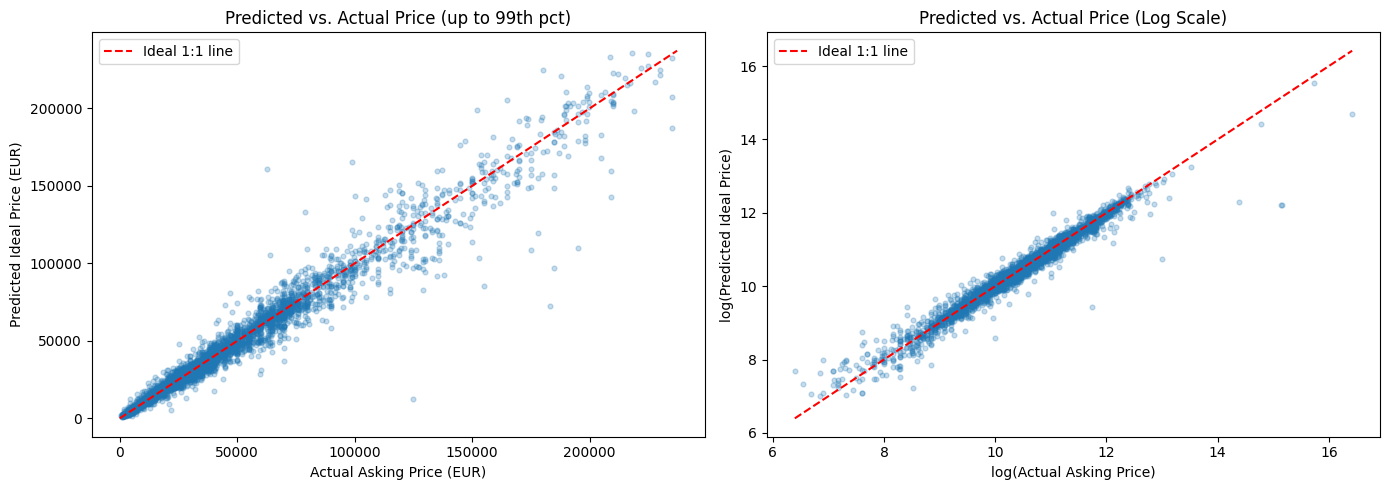

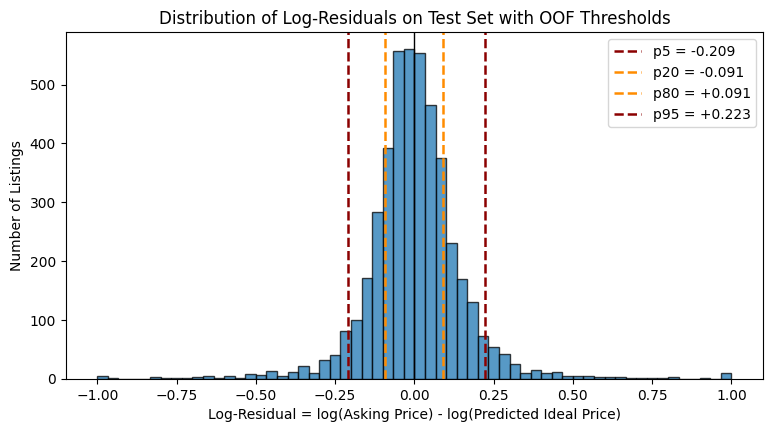

In [46]:
# Plot 1: Predicted vs Actual Price (Euro scale up to 99th percentile & Log scale)
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

p99_price = test_df["price"].quantile(0.99)
mask_99 = (test_df["price"] <= p99_price) & (test_df["ideal_price"] <= p99_price) & (~test_df["low_price_flag"])

axes[0].scatter(
    test_df.loc[mask_99, "price"],
    test_df.loc[mask_99, "ideal_price"],
    alpha=0.25, s=12
)
axes[0].plot([0, p99_price], [0, p99_price], color="red", linestyle="--", label="Ideal 1:1 line")
axes[0].set_title("Predicted vs. Actual Price (up to 99th pct)")
axes[0].set_xlabel("Actual Asking Price (EUR)")
axes[0].set_ylabel("Predicted Ideal Price (EUR)")
axes[0].legend()

clean_test = ~test_df["low_price_flag"]
axes[1].scatter(
    test_df.loc[clean_test, "log_price"],
    test_pred_log[clean_test],  # type: ignore
    alpha=0.25, s=12
)
min_log, max_log = test_df.loc[clean_test, "log_price"].min(), test_df.loc[clean_test, "log_price"].max()
axes[1].plot([min_log, max_log], [min_log, max_log], color="red", linestyle="--", label="Ideal 1:1 line")
axes[1].set_title("Predicted vs. Actual Price (Log Scale)")
axes[1].set_xlabel("log(Actual Asking Price)")
axes[1].set_ylabel("log(Predicted Ideal Price)")
axes[1].legend()

plt.tight_layout()
plt.savefig(FIGURES_FOLDER + "/price_predicted_vs_actual.png", dpi=150, bbox_inches="tight")
plt.show()

# Plot 2: Histogram of Test Residuals with Out-of-Fold Thresholds
plt.figure(figsize=(9, 4.5))
res_clipped = test_df.loc[clean_test, "price_residual"].clip(lower=-1.0, upper=1.0)
plt.hist(res_clipped, bins=60, alpha=0.75, edgecolor="black")

colors = ["darkred", "darkorange", "darkorange", "darkred"]
for p, thr, col in zip(RESIDUAL_PERCENTILES, residual_thresholds, colors):
    plt.axvline(thr, color=col, linestyle="--", linewidth=1.8, label=f"p{p} = {thr:+.3f}")

plt.axvline(0, color="black", linestyle="-", linewidth=1.0)
plt.title("Distribution of Log-Residuals on Test Set with OOF Thresholds")
plt.xlabel("Log-Residual = log(Asking Price) - log(Predicted Ideal Price)")
plt.ylabel("Number of Listings")
plt.legend()
plt.savefig(FIGURES_FOLDER + "/price_residuals_thresholds.png", dpi=150, bbox_inches="tight")
plt.show()

### 3.4. Prediction Intervals via Quantile Regression (p10 – p90)

To provide sellers and buyers with a direct price range in Euros (`[price_p10, price_p90]`), we train two additional LightGBM models with `objective="quantile"` at $\alpha = 0.10$ and $\alpha = 0.90$, and measure empirical coverage on the test set.

The $p10$ model acts as a safe lower bound (where only 10% of actual prices are expected to fall below), and the $p90$ model serves as an upper bound (where only 10% of actual prices are expected to fall above). Together, they create a robust 80% confidence interval that naturally filters out extreme market anomalies, offering users a realistic and actionable negotiation window.

Furthermore, by evaluating the "Median Relative Interval Width," we quantify market uncertainty at the individual listing level: a wider interval signals properties with highly unique characteristics or low market consensus, whereas a narrow interval indicates a highly standardized asset with strong pricing certainty.

In [47]:
quantile_params_base = {
    k: v for k, v in LGBM_PARAMS.items() if k != "objective"
}

model_q10 = lgb.LGBMRegressor(objective="quantile", alpha=0.10, **quantile_params_base)
model_q90 = lgb.LGBMRegressor(objective="quantile", alpha=0.90, **quantile_params_base)

model_q10.fit(X_train_lgb, y_train_log)
model_q90.fit(X_train_lgb, y_train_log)

test_df["ideal_price_p10"] = np.exp(model_q10.predict(X_test_lgb))  # type: ignore
test_df["ideal_price_p90"] = np.exp(model_q90.predict(X_test_lgb))  # type: ignore

within_interval = (
    (test_df["price"] >= test_df["ideal_price_p10"]) &
    (test_df["price"] <= test_df["ideal_price_p90"])
)
coverage_pct = within_interval.mean() * 100
median_rel_width = ((test_df["ideal_price_p90"] - test_df["ideal_price_p10"]) / test_df["ideal_price"]).median() * 100

print(f"Empirical p10-p90 Interval Coverage on Test Set: {coverage_pct:.2f}% (target: ~80.0%)")
print(f"Median Relative Interval Width ((p90 - p10) / ideal_price): {median_rel_width:.1f}%")

Empirical p10-p90 Interval Coverage on Test Set: 71.35% (target: ~80.0%)
Median Relative Interval Width ((p90 - p10) / ideal_price): 23.5%


### 3.5. Error Analysis & Feature Importance

We analyze where the price model makes the largest errors:
1. **By Price Tier (Market Segment):** economy vs. mid-range vs. luxury/supercars (> 100,000 EUR).
2. **By Model Sample Size in Training:** rare models (< 30 training listings) vs. well-represented models ($\ge$ 30 training listings).
3. **Top 15 Most Important Features** driving the LightGBM predictions.

=== ERROR BREAKDOWN BY PRICE TIER ===


,listings,median_price_euro,MAE_euro,MAPE_pct,MdAPE_pct
price_tier,,,,,
< 15k EUR,616,9000.0,1419.6,20.3,12.7
15k - 30k EUR,1483,24000.0,1950.8,8.5,6.3
30k - 60k EUR,1288,39950.0,3806.3,9.0,7.0
60k - 100k EUR,698,72900.0,6661.8,8.8,6.4
> 100k EUR (Luxury),441,146900.0,67302.6,11.0,6.7



=== ERROR BREAKDOWN BY MODEL RARITY ===


,listings,MAE_euro,MAPE_pct,MdAPE_pct
model_rarity,,,,
Common model (>= 30 train listings),3971,4309.3,9.7,6.8
Rare model (< 30 train listings),555,46645.2,16.7,11.0


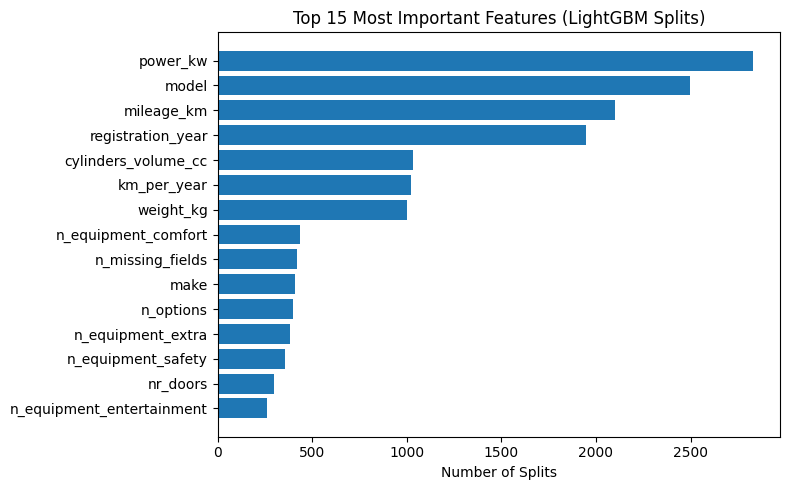

Saved: lgbm_price_model.joblib, price_model_config.json, train_with_price.csv, test_with_price.csv


In [48]:
# 1. Error breakdown by Price Tier (excluding suspicious < 500 EUR listings)
eval_df = test_df[~test_df["low_price_flag"]].copy()
eval_df["abs_error_euro"] = (eval_df["price"] - eval_df["ideal_price"]).abs()
eval_df["ape_%"] = eval_df["abs_error_euro"] / eval_df["price"] * 100

eval_df["price_tier"] = pd.cut(
    eval_df["price"],
    bins=[0, 15000, 30000, 60000, 100000, np.inf],
    labels=["< 15k EUR", "15k - 30k EUR", "30k - 60k EUR", "60k - 100k EUR", "> 100k EUR (Luxury)"]
)

error_by_tier = eval_df.groupby("price_tier", observed=False).agg(
    listings=("price", "count"),
    median_price_euro=("price", "median"),
    MAE_euro=("abs_error_euro", "mean"),
    MAPE_pct=("ape_%", "mean"),
    MdAPE_pct=("ape_%", "median"),
).round(1)

error_by_tier.to_csv(AUDIT_FOLDER + "/error_by_price_tier.csv")
print("=== ERROR BREAKDOWN BY PRICE TIER ===")
display(error_by_tier)

# 2. Error breakdown by Model Rarity in Training Set (< 30 listings vs >= 30 listings)
train_model_counts = train_df["model"].value_counts()
eval_df["train_model_count"] = eval_df["model"].map(train_model_counts).fillna(0)
eval_df["model_rarity"] = np.where(
    eval_df["train_model_count"] < 30,
    "Rare model (< 30 train listings)",
    "Common model (>= 30 train listings)"
)

error_by_rarity = eval_df.groupby("model_rarity").agg(
    listings=("price", "count"),
    MAE_euro=("abs_error_euro", "mean"),
    MAPE_pct=("ape_%", "mean"),
    MdAPE_pct=("ape_%", "median"),
).round(1)

error_by_rarity.to_csv(AUDIT_FOLDER + "/error_by_model_rarity.csv")
print("\n=== ERROR BREAKDOWN BY MODEL RARITY ===")
display(error_by_rarity)

# 3. Top 15 Feature Importances
feat_imp = pd.DataFrame({
    "feature": PRICE_FEATURES,
    "importance_splits": price_model.feature_importances_,
}).sort_values("importance_splits", ascending=False)

plt.figure(figsize=(8, 5))
top15 = feat_imp.head(15).iloc[::-1]
plt.barh(top15["feature"], top15["importance_splits"])
plt.title("Top 15 Most Important Features (LightGBM Splits)")
plt.xlabel("Number of Splits")
plt.tight_layout()
plt.savefig(AUDIT_FOLDER + "/price_feature_importance.png", dpi=150, bbox_inches="tight")
plt.show()

# 4. Save trained models, thresholds, and updated datasets with price predictions
joblib.dump(price_model, MODEL_DIR + "/lgbm_price_model.joblib")
joblib.dump(model_q10, MODEL_DIR + "/lgbm_price_q10.joblib")
joblib.dump(model_q90, MODEL_DIR + "/lgbm_price_q90.joblib")

price_artifacts = {
    "features": PRICE_FEATURES,
    "categorical_cols": PRICE_CATEGORICAL_COLS,
    "numerical_cols": PRICE_NUMERICAL_COLS,
    "train_categories": {col: list(X_train_lgb[col].cat.categories) for col in PRICE_CATEGORICAL_COLS},
    "residual_percentiles": RESIDUAL_PERCENTILES,
    "residual_thresholds": threshold_dict,
    "price_category_labels": PRICE_CATEGORY_LABELS,
}
with open(MODEL_DIR + "/price_model_config.json", "w", encoding="utf-8") as f:
    json.dump(price_artifacts, f, indent=2)

train_df.to_csv(DATA_FOLDER + "/train_with_price.csv", index=False)
test_df.to_csv(DATA_FOLDER + "/test_with_price.csv", index=False)

print("Saved: lgbm_price_model.joblib, price_model_config.json, train_with_price.csv, test_with_price.csv")

### 3.6. Testing models on two random ads

**Test 1**: We artificially generate a random car ad to test the price prediction model (along with the price range prediction).

**Test 2**: We artificially generate a random car ad containing also the requested price to test the market range classification model.

**Test 3**: We test the same random car ad from *Test 2*, but with a different price.

#### 3.6.1 Defining tests

In [49]:
def prepare_random_ad(make, model, registration_year, mileage_km, power_kw, asking_price=None):
    car_age = max(REFERENCE_YEAR - registration_year, 0)
    ad = {  # we insert some characteristics that are common to all test ads and some others that are different for each ad
        "make": make,
        "model": model,
        "vehicle_type": "Car",
        "body_type": "SUV",
        "body_color": "Black",
        "paint_type": "Metallic",
        "upholstery": "Cloth",
        "upholstery_color": "Black",
        "transmission": "Automatic",
        "drive_train": "4WD",
        "fuel_category": "Diesel",
        "primary_fuel": "Diesel",
        "envir_standard": "Euro 6",
        "original_market": "EU",
        "offer_type": "Used",
        "seller_type": "Dealer",
        "registration_year": registration_year,
        "car_age": car_age,
        "mileage_km": mileage_km,
        "km_per_year": mileage_km / max(car_age, 1),
        "power_kw": power_kw,
        "power_hp": power_kw * 1.35962,
        "cylinders": 4,
        "cylinders_volume_cc": 1968,
        "weight_kg": 1650,
        "nr_seats": 5,
        "nr_doors": 5,
        "gears": 8,
        "n_options": 20,
        "n_equipment_comfort": 6,
        "n_equipment_entertainment": 4,
        "n_equipment_extra": 3,
        "n_equipment_safety": 7,
        "n_missing_fields": 0,
        "is_used": True,
        "is_new": False,
        "is_preregistered": False,
        "had_accident": False,
        "has_full_service_history": True,
        "non_smoking": True,
        "is_rental": False,
        "has_particle_filter": True,
        "seller_is_dealer": True,
        "price_tax_deductible": True,
        "price_negotiable": True,
    }
    if asking_price is not None:
        ad["price"] = asking_price
    return pd.DataFrame([ad])

def predict_random_ad(ad):
    _, X_ad = prepare_lgbm_features(train_df, ad, PRICE_FEATURES, PRICE_CATEGORICAL_COLS)
    ideal_price = float(np.exp(price_model.predict(X_ad)[0]))   # type: ignore
    lower_bound = float(np.exp(model_q10.predict(X_ad)[0]))     # type: ignore
    upper_bound = float(np.exp(model_q90.predict(X_ad)[0]))     # type: ignore

    result = {
        "ideal_price_eur": ideal_price,
        "lower_bound_p10_eur": lower_bound,
        "upper_bound_p90_eur": upper_bound,
    }
    if "price" in ad.columns:
        residual = float(np.log(ad["price"].iloc[0]) - np.log(ideal_price))
        category = assign_price_categories(np.array([residual]), residual_thresholds)[0]
        result.update({
            "asking_price_eur": float(ad["price"].iloc[0]),
            "log_residual": residual,
            "price_category": str(category),
        })  # type: ignore
    return result

#### 3.6.2. Executing tests

In [50]:
with warnings.catch_warnings():
    warnings.simplefilter("ignore")
    
    # Test 1: New ad without price --> Output: ideal price & range (p10-p90 interval)
    test_ad_1 = prepare_random_ad(
        make="BMW", model="X3", registration_year=2020, mileage_km=65000, power_kw=140
    )
    test_1_result = predict_random_ad(test_ad_1)
    print("=== TEST 1: ESTIMATING IDEAL PRICE + RANGE ===")
    display(pd.DataFrame([test_1_result]).round(2))

    # Test 2: Existing ad with price --> Output: categorization of the ad
    test_ad_2 = prepare_random_ad(
        make="BMW", model="X3", registration_year=2020, mileage_km=65000, power_kw=140,
        asking_price=22900
    )
    test_2_result = predict_random_ad(test_ad_2)
    print("=== TEST 2: AD CATEGORIZATION ===")
    display(pd.DataFrame([test_2_result]).round(2))

    # Test 3: Existing ad with price --> Output: categorization of the ad
    test_ad_3 = prepare_random_ad(
        make="BMW", model="X3", registration_year=2020, mileage_km=65000, power_kw=140,
        asking_price=65000
    )
    test_3_result = predict_random_ad(test_ad_3)
    print("=== TEST 3: AD CATEGORIZATION ===")
    display(pd.DataFrame([test_3_result]).round(2))

=== TEST 1: ESTIMATING IDEAL PRICE + RANGE ===


,ideal_price_eur,lower_bound_p10_eur,upper_bound_p90_eur
0,24707.15,20968.06,29814.69


=== TEST 2: AD CATEGORIZATION ===


,ideal_price_eur,lower_bound_p10_eur,upper_bound_p90_eur,asking_price_eur,log_residual,price_category
0,24707.15,20968.06,29814.69,22900.0,-0.08,in_line


=== TEST 3: AD CATEGORIZATION ===


,ideal_price_eur,lower_bound_p10_eur,upper_bound_p90_eur,asking_price_eur,log_residual,price_category
0,24707.15,20968.06,29814.69,65000.0,0.97,well_above_market


## 4. Explainable Anomaly Detection
**Goal:** Identify listings with inconsistent or out-of-scale values using an unsupervised machine learning model (`\Isolation Forest`) and deterministic coherence rules. Extract explainable "attention signals".

### 4.1. Feature Engineering and Encoding for Anomaly Detection
Computing derived features to evaluate relative anomalies (e.g., price relative to age). Applying Ordinal Encoding for low-cardinality categorical variables and Frequency Encoding for high-cardinality ones to maintain interpretability.

In [51]:
# Computing derived features
for df in [train_df, test_df]:
    df["car_age"] = (REFERENCE_YEAR - df["registration_year"]).clip(lower=0)
    df["km_per_year"] = df["mileage_km"] / np.maximum(df["car_age"], 1)
    df["price_per_year"] = df["price"] / np.maximum(df["car_age"], 1)
    
    vol = df["cylinders_volume_cc"].replace(0, np.nan)
    df["hp_per_cc"] = df["power_hp"] / vol
    df["hp_per_cc"] = df["hp_per_cc"].fillna(0)

# Defining columns for encoding and filtering exclusions
ANOMALY_EXCLUDED_COLS = [
    "price_negotiable", 
    "price_tax_deductible", 
    "seller_is_dealer", 
    "n_missing_fields"
]

ORDINAL_COLS = [col for col in ["fuel_category", "transmission", "body_type"] if col not in ANOMALY_EXCLUDED_COLS]
FREQ_COLS = [col for col in ["make", "model"] if col not in ANOMALY_EXCLUDED_COLS]
NUMERICAL_ANOMALY_COLS = [col for col in PRICE_NUMERICAL_COLS + ["price", "price_per_year", "hp_per_cc"] if col not in ANOMALY_EXCLUDED_COLS]

X_train_if = train_df[NUMERICAL_ANOMALY_COLS].copy()
X_test_if = test_df[NUMERICAL_ANOMALY_COLS].copy()

# Applying encoding
for col in ORDINAL_COLS:
    if col in train_df.columns:
        X_train_if[col] = train_df[col].astype("category").cat.codes
        X_test_if[col] = pd.Categorical(test_df[col], categories=train_df[col].astype("category").cat.categories).codes

for col in FREQ_COLS:
    if col in train_df.columns:
        freq = train_df[col].value_counts(normalize=True)
        X_train_if[f"{col}_freq"] = train_df[col].map(freq).fillna(0)
        X_test_if[f"{col}_freq"] = test_df[col].map(freq).fillna(0)

# Filling missing values
X_train_if = X_train_if.fillna(0)
X_test_if = X_test_if.fillna(0)

# Displaying final features used for anomaly detection as a DataFrame without index
print(f"Total features passed to Isolation Forest and SHAP: {len(X_train_if.columns)}")

features_df = pd.DataFrame({
    "Feature": X_train_if.columns,
    "Data Type": X_train_if.dtypes.values
})

display(features_df.style.hide(axis="index"))

Total features passed to Isolation Forest and SHAP: 33


Feature,Data Type
registration_year,float64
car_age,float64
mileage_km,float64
km_per_year,float64
power_kw,float64
power_hp,float64
cylinders,float64
cylinders_volume_cc,float64
weight_kg,float64
nr_seats,float64


### 4.2. Isolation Forest Training and Risk Scoring
Training an Isolation Forest on all features, including price, generating an anomaly score and assigning risk categories by partitioning the negative score range. 

**Positive** scores are classified as *NONE* (no anomaly).

The **negative** scores (from the minimum training score up to 0) are split proportionally:
-   The lowest 34% defines *HIGH risk*.
-   The central 33% *MEDIUM risk*.
-   The highest 33% (up to 0) defines *LOW risk*.

In [52]:
# Training Isolation Forest
iso_forest = IsolationForest(n_estimators=300, random_state=SEED, n_jobs=-1)
iso_forest.fit(X_train_if)

# Computing anomaly scores
train_scores = iso_forest.decision_function(X_train_if)
test_scores = iso_forest.decision_function(X_test_if)

# Defining risk thresholds based on the range of negative scores on training
min_score = np.min(train_scores)

# Divide the negative range from min_score to 0 into 3 parts (34% high, 33% medium, 33% low)
high_threshold = min_score * 0.66   # Bottom 34% of the negative range
medium_threshold = min_score * 0.33 # Next 33% of the negative range
low_threshold = 0.0                 # Top 33% of the negative range

def assign_risk_category(scores, t_high, t_med, t_low):
    conditions = [
        scores < t_high,
        (scores >= t_high) & (scores < t_med),
        (scores >= t_med) & (scores < t_low),
        scores >= t_low
    ]
    return np.select(conditions, ["high", "medium", "low", "none"], default="none")

train_df["anomaly_score"] = train_scores
train_df["risk_category"] = assign_risk_category(train_scores, high_threshold, medium_threshold, low_threshold)

test_df["anomaly_score"] = test_scores
test_df["risk_category"] = assign_risk_category(test_scores, high_threshold, medium_threshold, low_threshold)

print("\nAnomaly Detection Summary:")
risk_summary = pd.DataFrame({
    "Risk Category": ["high", "medium", "low", "none"],
    "Train Count": [np.sum(train_df["risk_category"] == cat) for cat in ["high", "medium", "low", "none"]],
    "Test Count": [np.sum(test_df["risk_category"] == cat) for cat in ["high", "medium", "low", "none"]]
})
risk_summary["Train %"] = (risk_summary["Train Count"] / len(train_df) * 100).round(2)
risk_summary["Test %"] = (risk_summary["Test Count"] / len(test_df) * 100).round(2)
display(risk_summary)


Anomaly Detection Summary:


,Risk Category,Train Count,Test Count,Train %,Test %
0,high,50,16,0.28,0.35
1,medium,375,88,2.07,1.94
2,low,2254,526,12.45,11.62
3,none,15426,3897,85.20,86.08


#### 4.2.1 Plotting Isolation Forest anomaly scores

We plot the *anomaly scores* computed by the Isolation Forest model for each single ad in the test set, sorted from the lowest (biggest anomaly) to the highest (the most "normal" ad).

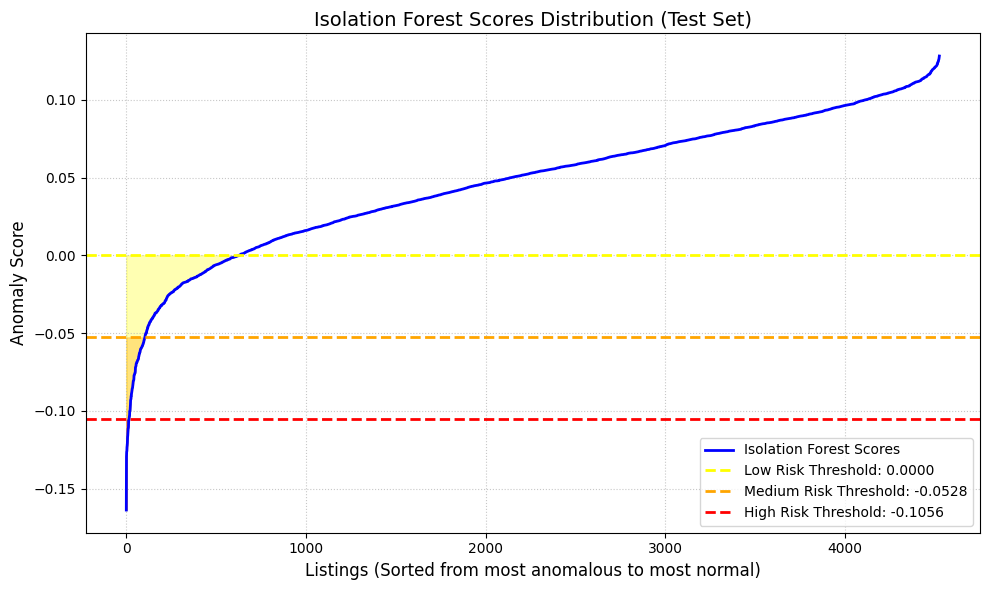

In [53]:
scores_to_plot = test_scores 

sorted_scores = np.sort(scores_to_plot)

plt.figure(figsize=(10, 6))
plt.plot(sorted_scores, color='blue', linewidth=2, label='Isolation Forest Scores')

plt.axhline(y=low_threshold, color='yellow', linestyle='--', linewidth=2, 
            label=f'Low Risk Threshold: {low_threshold:.4f}')
plt.axhline(y=medium_threshold, color='orange', linestyle='--', linewidth=2, 
            label=f'Medium Risk Threshold: {medium_threshold:.4f}')
plt.axhline(y=high_threshold, color='red', linestyle='--', linewidth=2, 
            label=f'High Risk Threshold: {high_threshold:.4f}')

plt.fill_between(range(len(sorted_scores)), sorted_scores, low_threshold, 
                 where=(sorted_scores <= low_threshold), color='yellow', alpha=0.3)
plt.fill_between(range(len(sorted_scores)), sorted_scores, medium_threshold, 
                 where=(sorted_scores <= medium_threshold), color='orange', alpha=0.3)
plt.fill_between(range(len(sorted_scores)), sorted_scores, high_threshold, 
                 where=(sorted_scores <= high_threshold), color='red', alpha=0.3)

plt.title('Isolation Forest Scores Distribution (Test Set)', fontsize=14)
plt.xlabel('Listings (Sorted from most anomalous to most normal)', fontsize=12)
plt.ylabel('Anomaly Score', fontsize=12)
plt.legend(loc='lower right', fontsize=10)
plt.grid(True, linestyle=':', alpha=0.7)

plt.tight_layout()
plt.savefig(FIGURES_FOLDER + "/if_test_scores_distribution.png", dpi=150, bbox_inches="tight")
plt.show()

### 4.3. Explainability with TreeSHAP
Extracting the top 3 features contributing to the anomaly score for high-risk listings. Pairing SHAP values with the specific listing value and the median value computed on comparable listings (same make, model, and age group).

In [54]:
# Instantiating SHAP TreeExplainer
explainer = shap.TreeExplainer(iso_forest)

high_risk_mask = test_df["risk_category"] == "high"
X_test_high_risk = X_test_if[high_risk_mask]

if not X_test_high_risk.empty:
    shap_values = explainer.shap_values(X_test_high_risk)
    
    # Pre-computing medians for comparables on the train set
    train_df["age_group"] = pd.cut(train_df["car_age"], bins=[-1, 3, 7, 12, 100], labels=["0-3", "4-7", "8-12", "12+"])
    test_df["age_group"] = pd.cut(test_df["car_age"], bins=[-1, 3, 7, 12, 100], labels=["0-3", "4-7", "8-12", "12+"])
    
    medians_df = train_df.groupby(["make", "model", "age_group"], observed=False)[NUMERICAL_ANOMALY_COLS].median()
    
    top_features_list = []
    feature_names = X_test_if.columns
    
    for i, idx_in_test in enumerate(X_test_high_risk.index):
        instance_shap = shap_values[i]
        sorted_indices = np.argsort(instance_shap)
        top_3_indices = sorted_indices[:3]
        
        row_data = test_df.loc[idx_in_test]
        make = row_data.get("make")
        model = row_data.get("model")
        age_grp = row_data.get("age_group")
        
        try:
            comparables_median = medians_df.loc[(make, model, age_grp)]     # type: ignore
        except KeyError:
            comparables_median = None
            
        top_features = []
        for idx in top_3_indices:
            feat_name = feature_names[idx]
            feat_val = X_test_high_risk.iloc[i, idx]
            
            if comparables_median is not None and feat_name in comparables_median and pd.notna(comparables_median[feat_name]):
                med_val = comparables_median[feat_name]
                ref_str = f", median of comparables = {med_val:.2f}"
            else:
                ref_str = ""
                
            contribution = instance_shap[idx]
            top_features.append(f"{feat_name} = {feat_val:.2f}{ref_str} [SHAP: {contribution:.2f}]")
            
        top_features_list.append(" | ".join(top_features))
        
    test_df.loc[high_risk_mask, "top_3_anomalous_features"] = top_features_list
else:
    test_df["top_3_anomalous_features"] = np.nan

joblib.dump(iso_forest, MODEL_DIR + "/iso_forest.joblib")

['data/models/iso_forest.joblib']

### 4.4. Deterministic Coherence Rules and Peer Comparison
Implementing deterministic checks for specific logical inconsistencies and calculating a robust Z-Score (using Median Absolute Deviation) to flag values that deviate significantly from peers.

In [55]:
def check_coherence_rules(row):
    signals = []
    
    if row.get("is_new") and row.get("mileage_km", 0) > 1000:
        signals.append("is_new with high mileage")
    if row.get("is_new") and row.get("is_used"):
        signals.append("is_new and is_used both true")
        
    if pd.notna(row.get("power_kw")) and pd.notna(row.get("power_hp")):
        expected_hp = row.get("power_kw") * 1.35962
        if abs(row.get("power_hp") - expected_hp) > 5:
            signals.append("power_hp inconsistent with power_kw")
            
    fuel = str(row.get("fuel_category")).lower()
    if fuel == "electric" and (row.get("cylinders", 0) > 0 or row.get("cylinders_volume_cc", 0) > 0):
        signals.append("electric car with displacement or cylinders")
        
    if row.get("registration_year", 0) > REFERENCE_YEAR:
        signals.append("registration in the future")
        
    if row.get("is_new") and row.get("nr_prev_owners", 0) > 0:
        signals.append("is_new with previous owners")
        
    return "; ".join(signals) if signals else "None"

test_df["coherence_signals"] = test_df.apply(check_coherence_rules, axis=1)

# Computing robust Z-Score
def robust_mad(x):
    mad = np.median(np.abs(x - np.median(x)))
    return mad * 1.4826 if mad > 0 else 1.0

peer_stats = train_df.groupby(["make", "model", "registration_year"]).agg(
    peer_price_median=("price", "median"),
    peer_price_mad=("price", robust_mad)
).reset_index()

test_df = test_df.drop(columns=["peer_price_median", "peer_price_mad"], errors="ignore")
test_df = test_df.merge(peer_stats, on=["make", "model", "registration_year"], how="left")
test_df["peer_price_mad"] = test_df["peer_price_mad"].replace(0, 1.0).fillna(1.0)
test_df["price_robust_zscore"] = (test_df["price"] - test_df["peer_price_median"]) / test_df["peer_price_mad"]

conditions = [
    test_df["price_robust_zscore"].isna(),
    test_df["price_robust_zscore"].abs() > 3
]
test_df["price_zscore_signal"] = np.select(conditions, ["None", "True"], default="False")

### 4.5. Testing the Explainable Anomaly Detection Pipeline
Run the anomaly detection models (*Isolation Forest*, *SHAP*, *Coherence Rules*) on the synthetic test ads generated in section ***3.6. Testing models on two random ads***, evaluating outputs on normal, extreme, and logically incoherent listings.

#### 4.5.1. Defining tests

In [56]:
def test_anomaly_pipeline(ad_df):
    if "price" not in ad_df.columns:
        return {"error": "Anomaly detection requires an asking price."}
        
    ad_eval = ad_df.copy().reset_index(drop=True)
    
    ad_eval["car_age"] = (REFERENCE_YEAR - ad_eval["registration_year"]).clip(lower=0)
    ad_eval["km_per_year"] = ad_eval["mileage_km"] / np.maximum(ad_eval["car_age"], 1)
    ad_eval["price_per_year"] = ad_eval["price"] / np.maximum(ad_eval["car_age"], 1)
    
    vol = ad_eval.get("cylinders_volume_cc", 0).iloc[0]
    if pd.isna(vol) or vol == 0:
        ad_eval["hp_per_cc"] = 0
    else:
        ad_eval["hp_per_cc"] = ad_eval["power_hp"] / vol
        
    # Encoding
    X_ad_if = pd.DataFrame(index=[0], columns=NUMERICAL_ANOMALY_COLS)
    for col in NUMERICAL_ANOMALY_COLS:
        X_ad_if[col] = ad_eval.get(col, 0)
            
    for col in ORDINAL_COLS:
        cat_type = train_df[col].astype("category")
        X_ad_if[col] = pd.Categorical(ad_eval[col], categories=cat_type.cat.categories).codes
        
    for col in FREQ_COLS:
        freq = train_df[col].value_counts(normalize=True)
        X_ad_if[f"{col}_freq"] = ad_eval[col].map(freq).fillna(0)
        
    X_ad_if = X_ad_if.fillna(0)
    
    # Isolation Forest & Risk Scoring
    score = iso_forest.decision_function(X_ad_if)[0]
    risk = assign_risk_category(np.array([score]), high_threshold, medium_threshold, low_threshold)[0]
    
    # TreeSHAP Explainability
    top_features_str = "None"
    if risk in ["high", "medium", "low"]:
        shap_vals = explainer.shap_values(X_ad_if)[0]
        top_3_indices = np.argsort(shap_vals)[:3] 
        
        make = str(ad_eval["make"].iloc[0]).strip().lower()
        model = str(ad_eval["model"].iloc[0]).strip().lower()
        age = ad_eval["car_age"].iloc[0]
        
        if age <= 3: age_grp = "0-3"
        elif age <= 7: age_grp = "4-7"
        elif age <= 12: age_grp = "8-12"
        else: age_grp = "12+"
        
        try:
            comparables_median = medians_df.loc[(make, model, age_grp)]     # type: ignore
        except KeyError:
            comparables_median = None
            
        top_features = []
        for idx in top_3_indices:
            feat_name = X_ad_if.columns[idx]
            feat_val = X_ad_if.iloc[0, idx]
            med_str = ""
            if comparables_median is not None and feat_name in comparables_median and pd.notna(comparables_median[feat_name]):
                med_str = f", median of comparables = {comparables_median[feat_name]:.2f}"
            top_features.append(f"{feat_name} = {feat_val:.2f}{med_str} [SHAP: {shap_vals[idx]:.2f}]")
        top_features_str = " | ".join(top_features)
        
    # Deterministic Coherence Rules
    coherence = check_coherence_rules(ad_eval.iloc[0])
    
    # Robust Z-Score against peers
    make_val, model_val, year_val = ad_eval["make"].iloc[0], ad_eval["model"].iloc[0], ad_eval["registration_year"].iloc[0]
    peer_match = peer_stats[(peer_stats["make"] == make_val) & 
                            (peer_stats["model"] == model_val) & 
                            (peer_stats["registration_year"] == year_val)]    

    z_score_signal = "None"
    if not peer_match.empty:
        med = peer_match["peer_price_median"].iloc[0]
        mad = peer_match["peer_price_mad"].iloc[0]
        z_score = (ad_eval["price"].iloc[0] - med) / mad
        z_score_signal = "True" if abs(z_score) > 3 else "False"

    return {
        "asking_price_eur": ad_eval["price"].iloc[0],
        "anomaly_score": round(score, 4),
        "risk_category": risk.upper(),
        "top_3_anomalous_features": top_features_str,
        "coherence_signals": coherence,
        "z_score_signal": z_score_signal
    }

#### 4.5.2. Executing tests

In [57]:
with warnings.catch_warnings():
    warnings.simplefilter("ignore")

    print("=== TEST 2: NORMAL PRICE AD (Expected: NONE risk, no anomalies) ===")
    display(pd.DataFrame([test_anomaly_pipeline(test_ad_2)]))
    
    print("\n=== TEST 3: HIGH PRICE AD (Expected: NONE risk with even lower anomaly_score in absolute value, no anomalies) ===")
    display(pd.DataFrame([test_anomaly_pipeline(test_ad_3)]))

    print("\n=== TEST 4: LOW RISK AD (Expected: LOW risk, no anomalies) ===")
    test_ad_4 = prepare_random_ad(
        make="BMW", model="X3", registration_year=2020, mileage_km=65000, power_kw=380,
        asking_price=22900
    )
    display(pd.DataFrame([test_anomaly_pipeline(test_ad_4)]))
    
    print("\n=== TEST 5: INCOHERENT AD (Expected: NONE risk, no anomalies, Coherence signals triggered) ===")
    test_ad_5 = test_ad_2.copy()
    test_ad_5["fuel_category"] = "Electric"  # Contradicts having 1968cc / 4 cylinders
    test_ad_5["is_new"] = True               # Contradicts having 65000 km
    
    display(pd.DataFrame([test_anomaly_pipeline(test_ad_5)]))

=== TEST 2: NORMAL PRICE AD (Expected: NONE risk, no anomalies) ===


,asking_price_eur,anomaly_score,risk_category,top_3_anomalous_features,coherence_signals,z_score_signal
0,22900,0.02,NONE,None,None,None



=== TEST 3: HIGH PRICE AD (Expected: NONE risk with even lower anomaly_score in absolute value, no anomalies) ===


,asking_price_eur,anomaly_score,risk_category,top_3_anomalous_features,coherence_signals,z_score_signal
0,65000,0.02,NONE,None,None,None



=== TEST 4: LOW RISK AD (Expected: LOW risk, no anomalies) ===


,asking_price_eur,anomaly_score,risk_category,top_3_anomalous_features,coherence_signals,z_score_signal
0,22900,-0.04,LOW,"has_particle_filter = 1.00, median of comparables = 0.00 [SHAP: -0.60] | body_type = -1.00 [SHAP: -0.51] | power_kw = 380.00, median of comparables = 140.00 [SHAP: -0.51]",None,None



=== TEST 5: INCOHERENT AD (Expected: NONE risk, no anomalies, Coherence signals triggered) ===


,asking_price_eur,anomaly_score,risk_category,top_3_anomalous_features,coherence_signals,z_score_signal
0,22900,0.01,NONE,None,is_new with high mileage; is_new and is_used both true; electric car with displacement or cylinders,None


### 4.6. Quantitative Evaluation via Synthetic Anomalies

Unsupervised model validation via synthetic anomaly injection. We corrupt approximately 20% of the test set by applying targeted modifications to price, mileage, age, and power. Subsequently, we evaluate both the **detection metrics** (*AUC-ROC*, *Average Precision*, *Recall*, *False Alarm Rate*) to understand if the model intercepts the anomaly, and the **attribution metrics** (*SHAP Top-1* and *Top-3*) to verify if the model correctly assigns the cause of the anomaly to the feature we manipulated.

In [58]:
print("=== MULTIPLE SYNTHETIC ANOMALY INJECTION (20%) AND VALIDATION ===")

synth_test = test_df.copy()
np.random.seed(SEED)

# Select 20% of the rows to corrupt
n_corrupt = int(len(synth_test) * 0.20)
corrupt_indices = np.random.choice(synth_test.index, size=n_corrupt, replace=False)

synth_test["is_synthetic_anomaly"] = 0
synth_test["anomaly_type"] = "Normal"
synth_test.loc[corrupt_indices, "is_synthetic_anomaly"] = 1

# Calculate how many ads will have 1, 2, or 3 anomalies
n1 = int(n_corrupt * 0.34)
n2 = int(n_corrupt * 0.33)

idx_1 = corrupt_indices[:n1]
idx_2 = corrupt_indices[n1:n1+n2]
idx_3 = corrupt_indices[n1+n2:]

# Group anomalies into 4 non-overlapping 'categories' to avoid logical conflicts 
# (e.g., assigning km_0 and km_x5 on the same car is forbidden)
anomaly_categories = [
    [("price_x3", ["price", "price_per_year"]), ("price_x0.3", ["price", "price_per_year"])],
    [("km_x5", ["mileage_km", "km_per_year"]), ("km_0", ["mileage_km", "km_per_year"])],
    [("year_minus_10", ["registration_year", "car_age", "km_per_year", "price_per_year"])],
    [("power_x3", ["power_kw", "power_hp", "hp_per_cc"])]
]

row_expected_features = {}

synth_test["injected_types"] = "" 
# Apply manipulations dynamically
for row_idx in corrupt_indices:
    if row_idx in idx_1: k = 1
    elif row_idx in idx_2: k = 2
    else: k = 3
    
    # Randomly select k distinct categories (e.g., Price and Power)
    chosen_cats = np.random.choice(range(len(anomaly_categories)), size=k, replace=False)
    expected_feats = []

    injected_names = []
    
    for cat_idx in chosen_cats:
        # Randomly pick a specific anomaly within the chosen category
        anom_name, feats = anomaly_categories[cat_idx][np.random.randint(len(anomaly_categories[cat_idx]))]
        expected_feats.extend(feats)

        injected_names.append(anom_name)
        
        # Execute the material corruption
        if anom_name == "price_x3": synth_test.at[row_idx, "price"] *= 3                        # type: ignore
        elif anom_name == "price_x0.3": synth_test.at[row_idx, "price"] *= 0.3                  # type: ignore
        elif anom_name == "km_x5": synth_test.at[row_idx, "mileage_km"] *= 5                    # type: ignore
        elif anom_name == "km_0": synth_test.at[row_idx, "mileage_km"] = 0
        elif anom_name == "year_minus_10": synth_test.at[row_idx, "registration_year"] -= 10    # type: ignore
        elif anom_name == "power_x3": 
            synth_test.at[row_idx, "power_kw"] *= 3                                             # type: ignore
            synth_test.at[row_idx, "power_hp"] *= 3                                             # type: ignore
            
    # Classify the row for the final output
    synth_test.at[row_idx, "anomaly_type"] = f"{k} Injected Anomalies"
    synth_test.at[row_idx, "injected_types"] = "+".join(sorted(injected_names))
    row_expected_features[row_idx] = list(set(expected_feats))

# Recalculate derived features on the ENTIRE synthetic dataset
synth_test["car_age"] = (REFERENCE_YEAR - synth_test["registration_year"]).clip(lower=0)
synth_test["km_per_year"] = synth_test["mileage_km"] / np.maximum(synth_test["car_age"], 1)
synth_test["price_per_year"] = synth_test["price"] / np.maximum(synth_test["car_age"], 1)

vol = synth_test["cylinders_volume_cc"].replace(0, np.nan)
synth_test["hp_per_cc"] = synth_test["power_hp"] / vol
synth_test["hp_per_cc"] = synth_test["hp_per_cc"].fillna(0)

# Feature Encoding for Isolation Forest
X_synth = synth_test[NUMERICAL_ANOMALY_COLS].copy()
for col in ORDINAL_COLS:
    cat_type = train_df[col].astype("category")
    X_synth[col] = pd.Categorical(synth_test[col], categories=cat_type.cat.categories).codes
for col in FREQ_COLS:
    freq = train_df[col].value_counts(normalize=True)
    X_synth[f"{col}_freq"] = synth_test[col].map(freq).fillna(0)
X_synth = X_synth.fillna(0)

# Scoring and Risk Assignment
synth_scores = iso_forest.decision_function(X_synth)
inverted_scores = -synth_scores # Higher values = higher risk

synth_test["anomaly_score"] = synth_scores
synth_test["risk_category"] = assign_risk_category(synth_scores, high_threshold, medium_threshold, low_threshold)
synth_test["is_anomalous"] = synth_test["risk_category"].isin(["high", "medium", "low"]).astype(int)

# --- GLOBAL DETECTION METRICS ---
y_true = synth_test["is_synthetic_anomaly"]
y_pred_prob = inverted_scores
y_pred_class = synth_test["is_anomalous"]

auc_roc = roc_auc_score(y_true, y_pred_prob)
avg_precision = average_precision_score(y_true, y_pred_prob)

tn, fp, fn, tp = confusion_matrix(y_true, y_pred_class).ravel()
recall = tp / (tp + fn)
false_alarm_rate = fp / (fp + tn)

print("--- GLOBAL DETECTION METRICS ---")
print(f"AUC-ROC:           {auc_roc:.4f}")
print(f"Average Precision: {avg_precision:.4f}")
print(f"Recall (Detection): {recall:.2%} (at Low/Medium/High Risk levels)")
print(f"False Alarm Rate:     {false_alarm_rate:.2%} (on unmodified ads)\n")

# --- ATTRIBUTION METRICS (SHAP) ---
print("--- ATTRIBUTION METRICS (SHAP TOP-1 / TOP-3) ---")

corrupted_mask = synth_test["is_synthetic_anomaly"] == 1
X_corrupted = X_synth[corrupted_mask]
synth_corrupted = synth_test[corrupted_mask].copy()

shap_vals_corrupted = explainer.shap_values(X_corrupted)

top1_correct = []
top3_correct = []

for i, row_idx in enumerate(synth_corrupted.index):
    expected_features = row_expected_features[row_idx]
    
    # Take absolute SHAP values to identify major contributions
    abs_shap = np.abs(shap_vals_corrupted[i])
    top_indices = np.argsort(-abs_shap) 
    top_features = X_synth.columns[top_indices].tolist()
    
    t1 = top_features[:1]
    t3 = top_features[:3]
    
    # It is a "Hit" (success) if AT LEAST ONE injected feature is detected in the top 1 or 3
    is_top1 = any(feat in t1 for feat in expected_features)
    is_top3 = any(feat in t3 for feat in expected_features)
    
    top1_correct.append(is_top1)
    top3_correct.append(is_top3)

synth_corrupted["shap_top1_hit"] = top1_correct
synth_corrupted["shap_top3_hit"] = top3_correct

attribution_results = synth_corrupted.groupby("anomaly_type").agg(
    n_samples=("anomaly_type", "count"),
    recall_detection=("is_anomalous", "mean"),
    shap_top1_accuracy=("shap_top1_hit", "mean"),
    shap_top3_accuracy=("shap_top3_hit", "mean")
).round(4)

attribution_results["recall_detection"] = (attribution_results["recall_detection"] * 100).round(2).astype(str) + "%"
attribution_results["shap_top1_accuracy"] = (attribution_results["shap_top1_accuracy"] * 100).round(2).astype(str) + "%"
attribution_results["shap_top3_accuracy"] = (attribution_results["shap_top3_accuracy"] * 100).round(2).astype(str) + "%"

attribution_results.to_csv(AUDIT_FOLDER + "/anomaly_attribution_multiple_metrics.csv")
display(attribution_results)

=== MULTIPLE SYNTHETIC ANOMALY INJECTION (20%) AND VALIDATION ===
--- GLOBAL DETECTION METRICS ---
AUC-ROC:           0.7410
Average Precision: 0.3991
Recall (Detection): 43.65% (at Low/Medium/High Risk levels)
False Alarm Rate:     14.44% (on unmodified ads)

--- ATTRIBUTION METRICS (SHAP TOP-1 / TOP-3) ---


,n_samples,recall_detection,shap_top1_accuracy,shap_top3_accuracy
anomaly_type,,,,
1 Injected Anomalies,307,24.76%,37.13%,57.0%
2 Injected Anomalies,298,44.3%,62.42%,86.91%
3 Injected Anomalies,300,62.33%,76.67%,96.33%


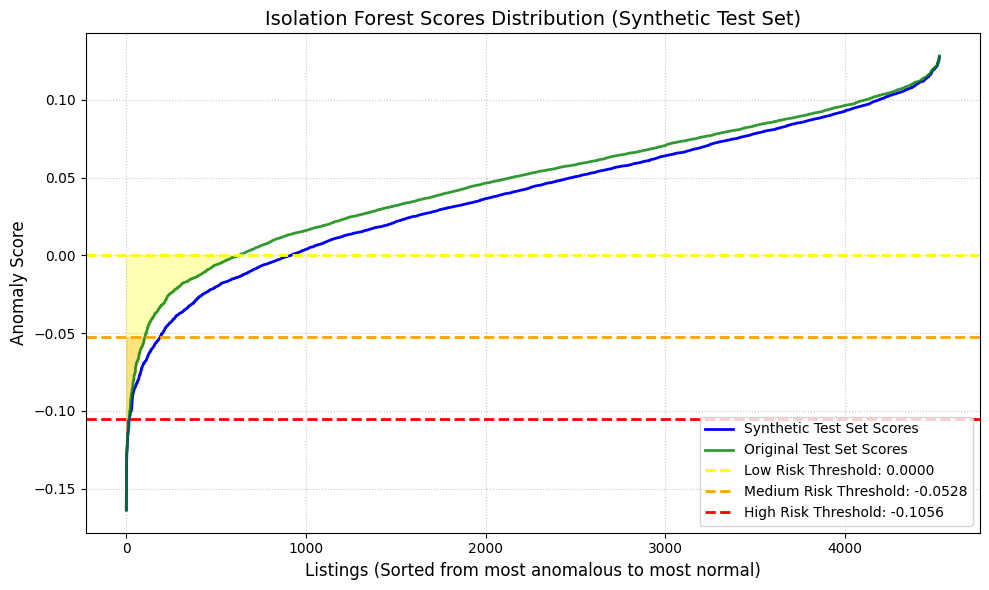

In [59]:
sorted_synth_scores = np.sort(synth_test["anomaly_score"])
sorted_test_scores = np.sort(test_scores)

plt.figure(figsize=(10, 6))
plt.plot(sorted_synth_scores, color='blue', linewidth=2, label='Synthetic Test Set Scores')
plt.plot(sorted_test_scores, color='green', linewidth=2, alpha=0.8, label='Original Test Set Scores')

plt.axhline(y=low_threshold, color='yellow', linestyle='--', linewidth=2, 
            label=f'Low Risk Threshold: {low_threshold:.4f}')
plt.axhline(y=medium_threshold, color='orange', linestyle='--', linewidth=2, 
            label=f'Medium Risk Threshold: {medium_threshold:.4f}')
plt.axhline(y=high_threshold, color='red', linestyle='--', linewidth=2, 
            label=f'High Risk Threshold: {high_threshold:.4f}')

plt.fill_between(range(len(sorted_scores)), sorted_scores, low_threshold, 
                 where=(sorted_scores <= low_threshold), color='yellow', alpha=0.3)
plt.fill_between(range(len(sorted_scores)), sorted_scores, medium_threshold, 
                 where=(sorted_scores <= medium_threshold), color='orange', alpha=0.3)
plt.fill_between(range(len(sorted_scores)), sorted_scores, high_threshold, 
                 where=(sorted_scores <= high_threshold), color='red', alpha=0.3)

plt.title('Isolation Forest Scores Distribution (Synthetic Test Set)', fontsize=14)
plt.xlabel('Listings (Sorted from most anomalous to most normal)', fontsize=12)
plt.ylabel('Anomaly Score', fontsize=12)
plt.legend(loc='lower right', fontsize=10)
plt.grid(True, linestyle=':', alpha=0.7)

plt.tight_layout()
plt.savefig(FIGURES_FOLDER + "/if_synth_test_scores_distribution.png", dpi=150, bbox_inches="tight")
plt.show()

## 5. Complete Assessment Pipeline
**Goal:** Define a single evaluation function that combines both price prediction and explainable anomaly detection pipelines, returning a complete JSON-ready assessment of a given car listing.

### 5.1. Unified Evaluation Function

#### 5.1.1. Defining function

In [60]:
def evaluate_listing(ad_df, return_json=False):
    price_results = predict_random_ad(ad_df)
    anomaly_results = test_anomaly_pipeline(ad_df)
    
    combined_result = {
        "asking_price": price_results.get("asking_price_eur"),
        "ideal_price": round(price_results.get("ideal_price_eur", 0.0), 2),
        "price_category": price_results.get("price_category"),
        "anomaly_score": anomaly_results.get("anomaly_score"),
        "risk_category": anomaly_results.get("risk_category"),
        "top_3_anomalous_features": anomaly_results.get("top_3_anomalous_features")
    }
    
    if return_json:
        return json.dumps(combined_result, indent=4)
        
    return combined_result

#### 5.1.2. Testing function

In [61]:
sample_ad = synth_test[synth_test["is_synthetic_anomaly"] == 1].sample(n=1, random_state=42)

display(sample_ad)

evaluation_json = evaluate_listing(sample_ad, return_json=True)
print(evaluation_json)

,original_row,price,price_tax_deductible,price_negotiable,make,model,mileage_km,vehicle_type,body_type,nr_seats,nr_doors,body_color,paint_type,upholstery,upholstery_color,power_kw,power_hp,transmission,gears,drive_train,cylinders,cylinders_volume_cc,weight_kg,has_particle_filter,fuel_category,primary_fuel,electric_range_km,electric_range_city_km,fuel_cons_comb_l100_km,co2_emission_grper_km,fuel_cons_comb_l100_wltp_km,fuel_cons_electric_comb_l100_wltp_km,co2_emission_grper_wltp_km,is_used,is_new,is_preregistered,had_accident,has_full_service_history,non_smoking,nr_prev_owners,is_rental,envir_standard,original_market,offer_type,country_code,seller_is_dealer,seller_type,registration_year,low_price_flag,high_power_flag,very_high_km_flag,year_beyond_reference_flag,new_and_used_flag,inconsistent_price_net_flag,invalid_vin_flag,n_missing_fields,car_age,km_per_year,n_options,n_equipment_comfort,n_equipment_entertainment,n_equipment_extra,n_equipment_safety,log_price,ideal_price,price_residual,price_category,ideal_price_p10,ideal_price_p90,price_per_year,hp_per_cc,anomaly_score,risk_category,age_group,top_3_anomalous_features,coherence_signals,peer_price_median,peer_price_mad,price_robust_zscore,price_zscore_signal,is_synthetic_anomaly,anomaly_type,injected_types,is_anomalous
327,44655,34700.0,True,False,alfa romeo,tonale,0.0,Car,Off-Road/Pick-up,5.0,5.0,Blue,Others,Full leather,unknown,288.0,393.0,Automatic,7.0,Front Wheel Drive,4.0,1500.0,1665.0,False,Electric/Gasoline,unknown,NaN,NaN,5.7,NaN,NaN,NaN,NaN,False,False,True,False,False,False,NaN,False,Euro 6,unknown,U,IT,True,Dealer,2024.0,False,False,False,False,False,False,False,16,1.0,0.0,4,3,0,1,0,10.45,34263.57,0.01,in_line,30345.2,36608.31,34700.0,0.26,-0.03,low,0-3,nan,None,29950.0,3039.33,1.56,False,1,2 Injected Anomalies,km_0+power_x3,1


{
    "asking_price": 34700.0,
    "ideal_price": 61492.89,
    "price_category": "well_below_market",
    "anomaly_score": -0.0289,
    "risk_category": "LOW",
    "top_3_anomalous_features": "is_preregistered = 1.00, median of comparables = 0.00 [SHAP: -1.03] | is_used = 0.00, median of comparables = 1.00 [SHAP: -0.85] | hp_per_cc = 0.26, median of comparables = 0.08 [SHAP: -0.50]"
}


## 6. Technical Validation, Coherence Rules and Figures
**Goal:** Quantify how often the coherence rules fire on real data, export the riskiest listings
for manual review, and produce the figures and tables used in the paper.

### 6.1. Frequency of Coherence Rules on the Real Dataset
Vectorized version of `check_coherence_rules`, extended with the remaining rules from the plan.
It is computed on the data BEFORE imputation (`*_with_missing`): median imputation
(e.g. 1995 cc displacement) would otherwise generate false signals.

In [62]:
def coherence_rule_masks(df):
    """Returns a dictionary {rule_name: boolean mask}."""
    def col(name, fill=0):
        return df[name].fillna(fill) if name in df.columns else pd.Series(fill, index=df.index)

    is_new = col("is_new", False).astype(bool)
    is_used = col("is_used", False).astype(bool)
    fuel = col("fuel_category", "").astype(str).str.strip().str.lower()     # type: ignore
    hp, kw = df.get("power_hp"), df.get("power_kw")

    return {
        "R1 is_new with mileage > 1,000 km": is_new & (col("mileage_km") > 1000),
        "R2 is_new and is_used both true": is_new & is_used,
        "R3 power_hp inconsistent with power_kw (> 5 hp)": (
            hp.notna() & kw.notna() & ((hp - kw * 1.35962).abs() > 5)
        ),
        "R4 electric car with cylinders/displacement": (fuel == "electric") & (
            (col("cylinders") > 0) | (col("cylinders_volume_cc") > 0)
        ),
        "R5 combustion car with electric range": fuel.isin(["diesel", "gasoline", "lpg", "cng"])
        & (col("electric_range_km") > 0),
        "R6 registration in the future": col("registration_year") > REFERENCE_YEAR,
        "R7 is_new with previous owners": is_new & (col("nr_prev_owners") > 0),
        "R8 is_new with declared accident": is_new & col("had_accident", False).astype(bool),
        "R9 km_per_year > 50,000": col("km_per_year") > 50000,
        "R10 used, age >= 3, km_per_year < 1,000": is_used & (col("car_age") >= 3)
        & (col("km_per_year") < 1000),
    }


def rule_frequency_table(df):
    masks = coherence_rule_masks(df)
    table = pd.DataFrame({
        "rule": list(masks),
        "listings": [int(m.sum()) for m in masks.values()],
    })
    table["share_%"] = (table["listings"] / len(df) * 100).round(2)
    any_rule = np.logical_or.reduce([m.values for m in masks.values()])
    total = pd.DataFrame([{
        "rule": "At least one rule",
        "listings": int(any_rule.sum()),
        "share_%": round(any_rule.mean() * 100, 2),
    }])
    return pd.concat([table, total], ignore_index=True)


full_with_missing = pd.concat([train_with_missing, test_with_missing], ignore_index=True)
rule_freq = rule_frequency_table(full_with_missing)     # type: ignore
rule_freq.to_csv(AUDIT_FOLDER + "/coherence_rules_frequency.csv", index=False)
print(f"Listings analysed: {len(full_with_missing)}")
display(rule_freq)

# Robust price z-score signal (Test set, against make/model/year peers)
zs = test_df["price_zscore_signal"].value_counts()
print("\nRobust z-score |z| > 3 on the Test set:")
print(f"  True: {zs.get('True', 0)} | False: {zs.get('False', 0)} | no peers (None): {zs.get('None', 0)}")

# Cross-tab between rules and Isolation Forest risk (on the imputed test set, indicative only)
test_any_rule = np.logical_or.reduce([m.values for m in coherence_rule_masks(test_df).values()])
cross = pd.crosstab(
    test_df["risk_category"],
    pd.Series(np.where(test_any_rule, "at least one rule", "no rule"), index=test_df.index),
    margins=True,
)
cross.to_csv(AUDIT_FOLDER + "/rules_vs_risk_crosstab.csv")
display(cross)

Listings analysed: 22632


,rule,listings,share_%
0,"R1 is_new with mileage > 1,000 km",0,0.00
1,R2 is_new and is_used both true,0,0.00
2,R3 power_hp inconsistent with power_kw (> 5 hp),0,0.00
3,R4 electric car with cylinders/displacement,28,0.12
4,R5 combustion car with electric range,1,0.00
5,R6 registration in the future,11,0.05
6,R7 is_new with previous owners,0,0.00
7,R8 is_new with declared accident,0,0.00
8,"R9 km_per_year > 50,000",146,0.65
9,"R10 used, age >= 3, km_per_year < 1,000",119,0.53



Robust z-score |z| > 3 on the Test set:
  True: 402 | False: 3965 | no peers (None): 160


col_0,at least one rule,no rule,All
risk_category,,,
high,3,13,16
low,13,513,526
medium,3,85,88
none,38,3859,3897
All,57,4470,4527


### 6.2. Export of the 30 Riskiest Listings for Manual Review
Takes the 30 Test set listings with the lowest anomaly score (all "high" plus the worst "medium").
For each one: top-3 SHAP features with the comparables' median, fired rules and z-score,
plus empty columns to be filled in by hand.

In [63]:
N_REVIEW = 30
order = np.argsort(test_df["anomaly_score"].values)[:N_REVIEW]  # type: ignore
review_X = X_test_if.iloc[order]
review_rows = test_df.iloc[order].copy()
review_shap = explainer.shap_values(review_X)
rule_masks_review = coherence_rule_masks(review_rows)

shap_cols = {f"shap_top{k}": [] for k in (1, 2, 3)}
rules_fired = []
for i in range(len(review_rows)):
    row = review_rows.iloc[i]
    try:
        comp = medians_df.loc[(row["make"], row["model"], row["age_group"])]    # type: ignore
    except KeyError:
        comp = None
    top3 = np.argsort(review_shap[i])[:3]
    for k, j in enumerate(top3, start=1):
        feat = review_X.columns[j]
        val = review_X.iloc[i, j]
        ref = ""
        if comp is not None and feat in comp and pd.notna(comp[feat]):
            ref = f", median of comparables = {comp[feat]:.2f}"
        shap_cols[f"shap_top{k}"].append(f"{feat} = {val:.2f}{ref} [SHAP: {review_shap[i][j]:.3f}]")
    fired = [name for name, m in rule_masks_review.items() if m.iloc[i]]
    rules_fired.append("; ".join(fired) if fired else "")

base_cols = [c for c in [
    "make", "model", "registration_year", "mileage_km", "km_per_year", "power_kw", "power_hp",
    "fuel_category", "body_type", "seller_type", "price", "ideal_price", "ideal_price_p10",
    "ideal_price_p90", "price_category", "anomaly_score", "risk_category",
    "price_robust_zscore", "price_zscore_signal",
] if c in review_rows.columns]

review_df = review_rows[base_cols].reset_index(drop=True)
for k, v in shap_cols.items():
    review_df[k] = v
review_df["fired_rules"] = rules_fired

# Columns to be filled in manually
review_df["verdict"] = ""      # "true_anomaly" / "false_positive" / "unsure"
review_df["issue_type"] = ""   # e.g. "wrong_price", "wrong_mileage", "rare_supercar", "classic_car"
review_df["notes"] = ""

review_path = AUDIT_FOLDER + "/manual_review_top30.csv"
if os.path.exists(review_path):
    print(f"{review_path} already exists: not overwritten (delete it to regenerate).")
else:
    review_df.to_csv(review_path, index=False, sep=";", decimal=",", encoding="utf-8-sig")
    print(f"Saved: {review_path}")
display(review_df.head(10))

data/audit/manual_review_top30.csv already exists: not overwritten (delete it to regenerate).


,make,model,registration_year,mileage_km,km_per_year,power_kw,power_hp,fuel_category,body_type,seller_type,price,ideal_price,ideal_price_p10,ideal_price_p90,price_category,anomaly_score,risk_category,price_robust_zscore,price_zscore_signal,shap_top1,shap_top2,shap_top3,fired_rules,verdict,issue_type,notes
0,mercedes-benz,amg one,2024.0,50.0,50.00,782.0,1063.0,Electric/Gasoline,Coupe,Dealer,3.75e+06,2.04e+05,84551.73,6.86e+05,well_above_market,-0.16,high,NaN,None,price_per_year = 3750000.00 [SHAP: -0.991],price = 3750000.00 [SHAP: -0.729],is_used = 0.00 [SHAP: -0.673],,,,
1,bugatti,divo,2020.0,1260.0,252.00,1103.0,1500.0,Gasoline,Coupe,Dealer,1.35e+07,2.43e+06,56152.79,2.15e+06,well_above_market,-0.13,high,NaN,None,price_per_year = 2700000.00 [SHAP: -1.138],price = 13500000.00 [SHAP: -0.768],power_kw = 1103.00 [SHAP: -0.579],"R10 used, age >= 3, km_per_year < 1,000",,,
2,bugatti,chiron,2023.0,1583.0,791.50,1103.0,1500.0,Gasoline,Coupe,Dealer,6.80e+06,5.66e+06,114698.59,6.95e+06,above_market,-0.13,high,2.81,False,"price_per_year = 3399500.00, median of comparables = 2632250.00 [SHAP: -1.126]","price = 6799000.00, median of comparables = 5514500.00 [SHAP: -0.757]","power_kw = 1103.00, median of comparables = 1103.00 [SHAP: -0.571]",,,,
3,bmw,m5,2025.0,1000.0,1000.00,535.0,727.0,Electric/Gasoline,Station wagon,Dealer,1.47e+05,1.79e+05,117851.37,1.79e+05,below_market,-0.13,high,-0.19,False,"price_per_year = 146900.00, median of comparables = 129995.00 [SHAP: -0.640]","n_equipment_extra = 22.00, median of comparables = 7.50 [SHAP: -0.640]","power_hp = 727.00, median of comparables = 625.00 [SHAP: -0.532]",,,,
4,maserati,mc20,2025.0,1.0,1.00,463.0,630.0,Gasoline,Other,Dealer,2.88e+05,2.43e+05,89525.45,2.49e+05,above_market,-0.12,high,28100.00,True,"price_per_year = 288000.00, median of comparables = 259900.00 [SHAP: -0.832]","is_used = 0.00, median of comparables = 1.00 [SHAP: -0.762]","is_preregistered = 1.00, median of comparables = 0.00 [SHAP: -0.680]",,,,
5,mercedes-benz,g 63 amg,2024.0,15320.0,15320.00,430.0,585.0,Electric/Gasoline,Off-Road/Pick-up,PrivateSeller,2.22e+05,2.26e+05,184271.76,2.26e+05,in_line,-0.12,high,0.31,False,"price_per_year = 222000.00, median of comparables = 229990.00 [SHAP: -0.839]","n_equipment_extra = 18.00, median of comparables = 3.00 [SHAP: -0.642]","has_particle_filter = 1.00, median of comparables = 0.00 [SHAP: -0.543]",,,,
6,porsche,macan,2025.0,50.0,50.00,470.0,639.0,Electric,Off-Road/Pick-up,Dealer,1.29e+05,1.38e+05,115318.83,1.39e+05,in_line,-0.12,high,5.71,True,"is_preregistered = 1.00, median of comparables = 0.00 [SHAP: -0.845]","is_used = 0.00, median of comparables = 1.00 [SHAP: -0.682]","power_kw = 470.00, median of comparables = 195.00 [SHAP: -0.532]",,,,
7,volvo,v60,2020.0,47000.0,9400.00,3.0,4.0,Others,Other,PrivateSeller,1.60e+04,2.51e+04,11569.06,2.58e+04,well_below_market,-0.12,high,-0.82,False,transmission = 3.00 [SHAP: -0.687],"gears = 1.00, median of comparables = 8.00 [SHAP: -0.611]","nr_seats = 1.00, median of comparables = 5.00 [SHAP: -0.501]",,,,
8,bugatti,veyron,2008.0,6625.0,389.71,736.0,1001.0,Gasoline,Coupe,Dealer,2.60e+06,1.84e+06,43529.89,1.95e+06,well_above_market,-0.12,high,NaN,None,price = 2600000.00 [SHAP: -0.700],price_per_year = 152941.18 [SHAP: -0.618],power_kw = 736.00 [SHAP: -0.560],"R10 used, age >= 3, km_per_year < 1,000",,,
9,audi,rs q8,2025.0,100.0,100.00,471.0,640.0,Electric/Gasoline,Off-Road/Pick-up,Dealer,1.73e+05,1.71e+05,140474.86,1.80e+05,in_line,-0.11,high,0.96,False,"is_preregistered = 1.00, median of comparables = 0.00 [SHAP: -0.783]","is_used = 0.00, median of comparables = 1.00 [SHAP: -0.727]","price_per_year = 172800.00, median of comparables = 159900.00 [SHAP: -0.664]",,,,


#### 6.2.1. Summary of the Manual Review
Run this cell after filling in `verdict` and `issue_type` in Excel and saving the same file.

In [64]:
annotated = pd.read_csv(review_path, sep=";", decimal=",", encoding="utf-8-sig")
annotated["verdict"] = annotated["verdict"].fillna("not_reviewed")
summary_verdict = annotated["verdict"].value_counts().rename_axis("verdict").to_frame("listings")
summary_verdict["%"] = (summary_verdict["listings"] / len(annotated) * 100).round(1)
display(summary_verdict)

fp = annotated[annotated["verdict"] == "false_positive"]
if not fp.empty:
    print("Typical false positives:")
    display(fp["issue_type"].value_counts())
    print("Most frequent top-1 SHAP feature among false positives:")
    display(fp["shap_top1"].str.split(" = ").str[0].value_counts())
precision_manual = (annotated["verdict"] == "true_anomaly").mean() * 100
print(f"Manual precision on the top-{len(annotated)}: {precision_manual:.1f}%")

,listings,%
verdict,,
false_positive,23,76.7
unsure,4,13.3
true_anomaly,3,10.0


Typical false positives:


issue_type
km_zero_premium        13
rare_supercar           5
premium_suv             3
imputation_artifact     2
Name: count, dtype: int64

Most frequent top-1 SHAP feature among false positives:


shap_top1
price_per_year      14
is_preregistered     8
price                1
Name: count, dtype: int64

Manual precision on the top-30: 10.0%


### 6.3. Figures and Tables

#### 6.3.1. Error Distribution (Test set log residuals with OOF thresholds)

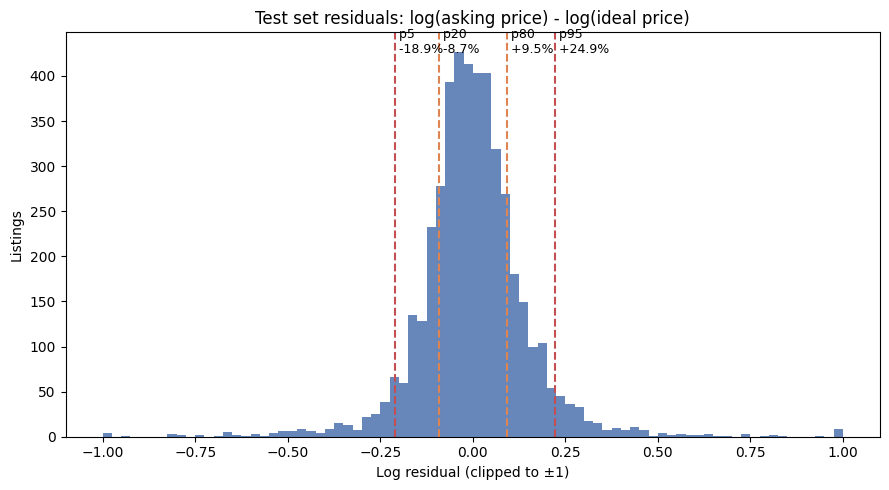

In [65]:
test_resid = np.log(test_df["price"]) - np.log(test_df["ideal_price"])
test_resid = test_resid[~test_df["low_price_flag"]]     # exclude suspicious prices < 500 EUR, as in Section 3
p5, p20, p80, p95 = np.percentile(oof_residuals, [5, 20, 80, 95])

fig, ax = plt.subplots(figsize=(9, 5))
ax.hist(test_resid.clip(-1, 1), bins=80, color="#4C72B0", alpha=0.85)
for v, lab in [(p5, "p5"), (p20, "p20"), (p80, "p80"), (p95, "p95")]:
    ax.axvline(v, color="#C44E52" if lab in ("p5", "p95") else "#DD8452", ls="--", lw=1.5)
    ax.text(v, ax.get_ylim()[1] * 0.95, f" {lab}\n {np.expm1(v)*100:+.1f}%", fontsize=9)
ax.set_title("Test set residuals: log(asking price) - log(ideal price)")
ax.set_xlabel("Log residual (clipped to ±1)")
ax.set_ylabel("Listings")
plt.tight_layout()
plt.savefig(FIGURES_FOLDER + "/fig_residual_distribution.png", dpi=150, bbox_inches="tight")
plt.show()

#### 6.3.2. MdAPE and MAE by Price Tier (from `error_by_tier`)

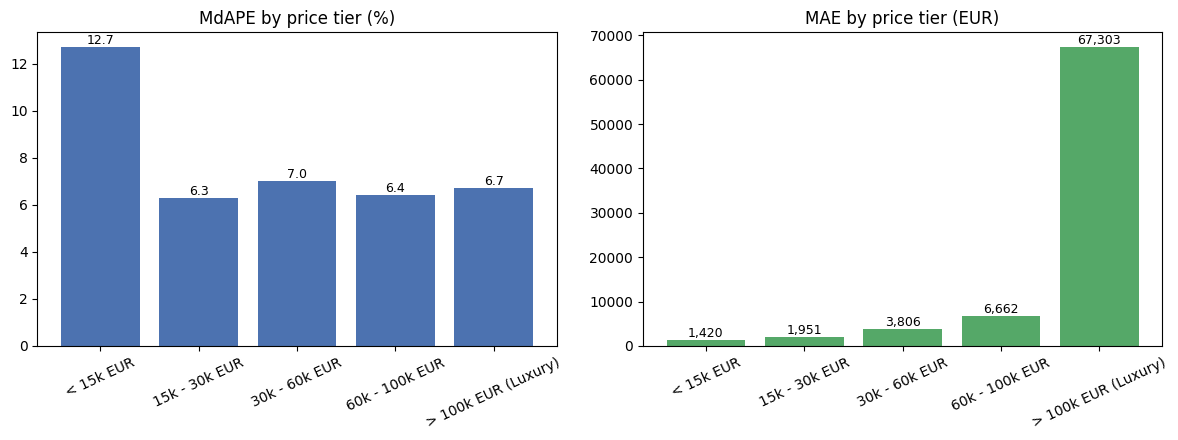

In [66]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
labels = error_by_tier.index.astype(str)
axes[0].bar(labels, error_by_tier["MdAPE_pct"], color="#4C72B0")
axes[0].set_title("MdAPE by price tier (%)")
axes[1].bar(labels, error_by_tier["MAE_euro"], color="#55A868")
axes[1].set_title("MAE by price tier (EUR)")
for ax, colname in zip(axes, ["MdAPE_pct", "MAE_euro"]):
    ax.tick_params(axis="x", rotation=25)
    for x, y in enumerate(error_by_tier[colname]):
        ax.text(x, y, f"{y:,.1f}" if colname == "MdAPE_pct" else f"{y:,.0f}", ha="center", va="bottom", fontsize=9)
plt.tight_layout()
plt.savefig(FIGURES_FOLDER + "/fig_error_by_tier.png", dpi=150, bbox_inches="tight")
plt.show()

#### 6.3.3. p10–p90 Interval Coverage (by tier, plus 40 example listings)

,count,coverage_%
price_tier,,
< 15k,616,69.2
15–30k,1483,73.6
30–60k,1288,70.9
60–100k,698,70.9
> 100k,441,68.9


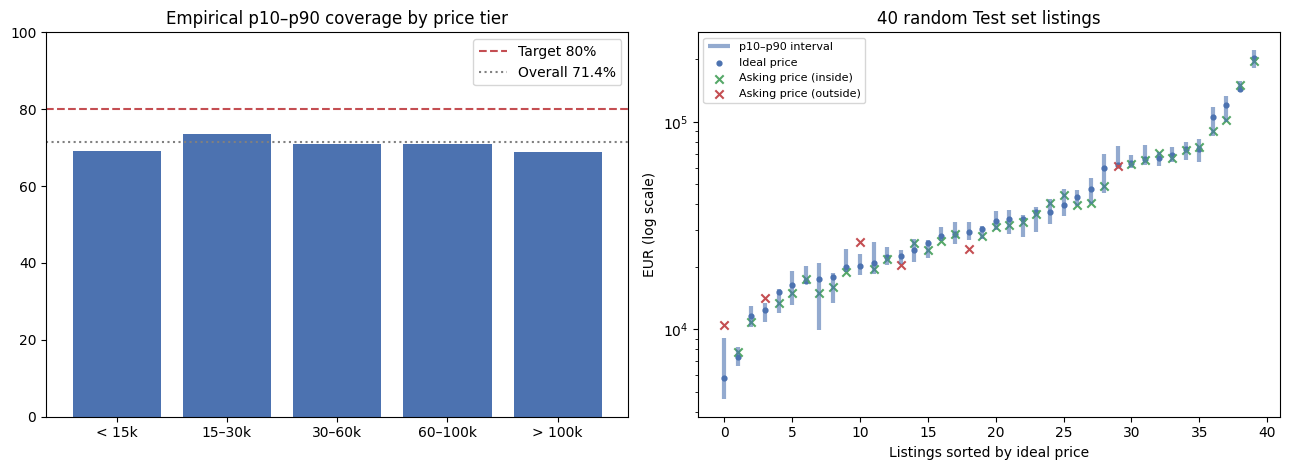

In [67]:
cov_df = test_df[~test_df["low_price_flag"]].copy()
cov_df["inside"] = (cov_df["price"] >= cov_df["ideal_price_p10"]) & (cov_df["price"] <= cov_df["ideal_price_p90"])
cov_df["price_tier"] = pd.cut(cov_df["price"], bins=[0, 15000, 30000, 60000, 100000, np.inf],
                              labels=["< 15k", "15–30k", "30–60k", "60–100k", "> 100k"])
coverage_by_tier = cov_df.groupby("price_tier", observed=False)["inside"].agg(["mean", "count"])
coverage_by_tier["coverage_%"] = (coverage_by_tier["mean"] * 100).round(1)
coverage_by_tier[["count", "coverage_%"]].to_csv(AUDIT_FOLDER + "/interval_coverage_by_tier.csv")
display(coverage_by_tier[["count", "coverage_%"]])

fig, axes = plt.subplots(1, 2, figsize=(13, 4.8))
axes[0].bar(coverage_by_tier.index.astype(str), coverage_by_tier["coverage_%"], color="#4C72B0")
axes[0].axhline(80, color="#C44E52", ls="--", label="Target 80%")
axes[0].axhline(cov_df["inside"].mean() * 100, color="gray", ls=":", label=f"Overall {cov_df['inside'].mean()*100:.1f}%")
axes[0].set_ylim(0, 100)
axes[0].set_title("Empirical p10–p90 coverage by price tier")
axes[0].legend()

sample = cov_df.sample(40, random_state=1234).sort_values("ideal_price").reset_index(drop=True)
x = np.arange(len(sample))
axes[1].vlines(x, sample["ideal_price_p10"], sample["ideal_price_p90"], color="#4C72B0", lw=3, alpha=0.6, label="p10–p90 interval")
axes[1].scatter(x, sample["ideal_price"], color="#4C72B0", s=12, label="Ideal price")
axes[1].scatter(x[sample["inside"]], sample.loc[sample["inside"], "price"], color="#55A868", marker="x", label="Asking price (inside)")
axes[1].scatter(x[~sample["inside"]], sample.loc[~sample["inside"], "price"], color="#C44E52", marker="x", label="Asking price (outside)")
axes[1].set_yscale("log")
axes[1].set_title("40 random Test set listings")
axes[1].set_xlabel("Listings sorted by ideal price")
axes[1].set_ylabel("EUR (log scale)")
axes[1].legend(fontsize=8)
plt.tight_layout()
plt.savefig(FIGURES_FOLDER + "/fig_interval_coverage.png", dpi=150, bbox_inches="tight")
plt.show()

#### 6.3.4. Recall by Synthetic Anomaly Type
Uses the `injected_types` column created in Section 4.6.
The "single" columns are the clean comparison: those rows contain only one anomaly type.

,anomaly_type,n_total,recall_all_%,n_single,recall_single_%,recall_single_high_medium_%
0,price_x3,203,49.8,35,17.1,2.9
1,price_x0.3,259,37.5,45,11.1,2.2
2,km_x5,249,52.6,37,24.3,5.4
3,km_0,216,38.9,45,4.4,2.2
4,year_minus_10,437,46.2,70,22.9,1.4
5,power_x3,439,65.1,75,50.7,13.3


,n,recall
anomaly_type,,
1 Injected Anomalies,307,24.8
2 Injected Anomalies,298,44.3
3 Injected Anomalies,300,62.3


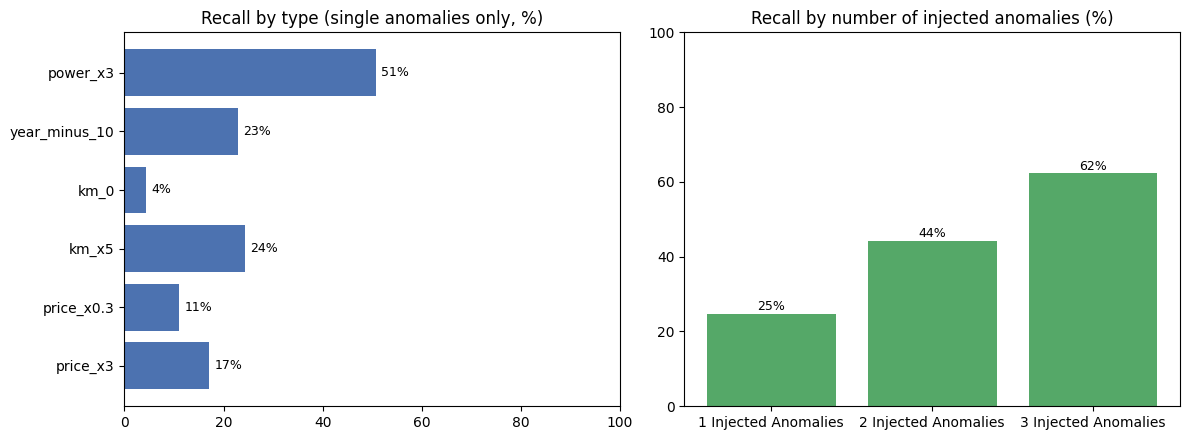

In [68]:
corr = synth_test[synth_test["is_synthetic_anomaly"] == 1].copy()
types = ["price_x3", "price_x0.3", "km_x5", "km_0", "year_minus_10", "power_x3"]

rows = []
for t in types:
    has_t = corr["injected_types"].str.split("+").apply(lambda l: t in l)
    only_t = corr["injected_types"] == t
    rows.append({
        "anomaly_type": t,
        "n_total": int(has_t.sum()),
        "recall_all_%": round(corr.loc[has_t, "is_anomalous"].mean() * 100, 1),
        "n_single": int(only_t.sum()),
        "recall_single_%": round(corr.loc[only_t, "is_anomalous"].mean() * 100, 1) if only_t.any() else np.nan,
        "recall_single_high_medium_%": round(corr.loc[only_t, "risk_category"].isin(["high", "medium"]).mean() * 100, 1) if only_t.any() else np.nan,
    })
recall_by_type = pd.DataFrame(rows)
recall_by_k = corr.groupby("anomaly_type")["is_anomalous"].agg(n="count", recall="mean")
recall_by_k["recall"] = (recall_by_k["recall"] * 100).round(1)

recall_by_type.to_csv(AUDIT_FOLDER + "/recall_by_anomaly_type.csv", index=False)
recall_by_k.to_csv(AUDIT_FOLDER + "/recall_by_n_anomalies.csv")
display(recall_by_type)
display(recall_by_k)

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
axes[0].barh(recall_by_type["anomaly_type"], recall_by_type["recall_single_%"], color="#4C72B0")
axes[0].set_xlim(0, 100)
axes[0].set_title("Recall by type (single anomalies only, %)")
for y, v in enumerate(recall_by_type["recall_single_%"]):
    axes[0].text(v + 1, y, f"{v:.0f}%", va="center", fontsize=9)
axes[1].bar(recall_by_k.index, recall_by_k["recall"], color="#55A868")
axes[1].set_ylim(0, 100)
axes[1].set_title("Recall by number of injected anomalies (%)")
for x, v in enumerate(recall_by_k["recall"]):
    axes[1].text(x, v + 1, f"{v:.0f}%", ha="center", fontsize=9)
plt.tight_layout()
plt.savefig(FIGURES_FOLDER + "/fig_recall_by_anomaly_type.png", dpi=150, bbox_inches="tight")
plt.show()

#### 6.3.5. Example Report (JSON for the appendix)
Runs a real "high" or "medium" risk Test set listing through the complete pipeline.

In [69]:
candidates = test_df[test_df["risk_category"].isin(["high", "medium"])]
example_ad = candidates.iloc[[0]] if not candidates.empty else test_df.iloc[[0]]
display(example_ad)

example_report = evaluate_listing(example_ad, return_json=True)
if isinstance(example_report, str):
    example_report = json.loads(example_report)

with open(AUDIT_FOLDER + "/example_report.json", "w", encoding="utf-8") as f:
    json.dump(example_report, f, indent=2, ensure_ascii=False, default=str)
print(json.dumps(example_report, indent=2, ensure_ascii=False, default=str))

,original_row,price,price_tax_deductible,price_negotiable,make,model,mileage_km,vehicle_type,body_type,nr_seats,nr_doors,body_color,paint_type,upholstery,upholstery_color,power_kw,power_hp,transmission,gears,drive_train,cylinders,cylinders_volume_cc,weight_kg,has_particle_filter,fuel_category,primary_fuel,electric_range_km,electric_range_city_km,fuel_cons_comb_l100_km,co2_emission_grper_km,fuel_cons_comb_l100_wltp_km,fuel_cons_electric_comb_l100_wltp_km,co2_emission_grper_wltp_km,is_used,is_new,is_preregistered,had_accident,has_full_service_history,non_smoking,nr_prev_owners,is_rental,envir_standard,original_market,offer_type,country_code,seller_is_dealer,seller_type,registration_year,low_price_flag,high_power_flag,very_high_km_flag,year_beyond_reference_flag,new_and_used_flag,inconsistent_price_net_flag,invalid_vin_flag,n_missing_fields,car_age,km_per_year,n_options,n_equipment_comfort,n_equipment_entertainment,n_equipment_extra,n_equipment_safety,log_price,ideal_price,price_residual,price_category,ideal_price_p10,ideal_price_p90,price_per_year,hp_per_cc,anomaly_score,risk_category,age_group,top_3_anomalous_features,coherence_signals,peer_price_median,peer_price_mad,price_robust_zscore,price_zscore_signal
4,105299,118890.0,False,True,rolls-royce,ghost,36922.0,Car,Sedan,5.0,4.0,Black,unknown,unknown,unknown,420.0,571.0,Automatic,8.0,Rear Wheel Drive,12.0,6592.0,2435.0,False,Gasoline,Regular/Benzine 91,NaN,NaN,13.6,NaN,NaN,NaN,NaN,True,False,False,False,False,False,0.0,False,unknown,unknown,U,IT,True,Dealer,2010.0,False,False,False,False,False,False,False,11,15.0,2461.47,0,0,0,0,0,11.69,146398.49,-0.21,below_market,39358.07,334981.76,7926.0,0.09,-0.06,medium,12+,nan,None,NaN,1.0,NaN,None


{
  "asking_price": 118890.0,
  "ideal_price": 146398.49,
  "price_category": "below_market",
  "anomaly_score": -0.0649,
  "risk_category": "MEDIUM",
  "top_3_anomalous_features": "power_kw = 420.00, median of comparables = 419.00 [SHAP: -0.53] | make_freq = 0.00 [SHAP: -0.47] | cylinders_volume_cc = 6592.00, median of comparables = 6592.00 [SHAP: -0.44]"
}
